In [ ]:
import polars as pl
df = pl.read_parquet("/content/drive/MyDrive/test_dissertation_sample.parquet")

In [ ]:
import os
output_file = "/content/drive/MyDrive/test_dissertation_sample.parquet"
os.makedirs(os.path.dirname(output_file), exist_ok=True)

df.write_parquet(output_file, compression="snappy")
print(f"💾 Saved dissertation sample to: {output_file}")

💾 Saved dissertation sample to: /content/drive/MyDrive/test_dissertation_sample.parquet


In [ ]:
import polars as pl
import numpy as np
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

def stratified_loan_split(df, test_size=0.3, random_state=42):

    loan_summary = df.group_by('LOAN_ID').agg([
        pl.col('event').max().alias('ever_defaults'),
        pl.col('ORIG_DATE').first(),
        pl.col('CSCORE_B').first().alias('credit_score'),
        pl.col('OLTV').first().alias('ltv'),
        pl.col('DTI').first().alias('dti'),
        pl.col('PURPOSE').first().alias('purpose'),
        pl.col('data_quarter').min().alias('first_quarter'),
        pl.col('data_quarter').max().alias('last_quarter'),
        pl.col('data_quarter').count().alias('total_obs')
    ])

    print("🏗️ Creating stratification variables...")

    loan_summary = loan_summary.with_columns([
        # Credit tier
        pl.when(pl.col('credit_score') < 620)
        .then(pl.lit('VeryLow'))
        .when(pl.col('credit_score') < 680)
        .then(pl.lit('Low'))
        .when(pl.col('credit_score') < 740)
        .then(pl.lit('Mid'))
        .when(pl.col('credit_score') < 800)
        .then(pl.lit('High'))
        .otherwise(pl.lit('VeryHigh'))
        .alias('credit_tier'),

        # LTV tier
        pl.when(pl.col('ltv') < 70)
        .then(pl.lit('LowLTV'))
        .when(pl.col('ltv') < 85)
        .then(pl.lit('MidLTV'))
        .otherwise(pl.lit('HighLTV'))
        .alias('ltv_tier'),

        # DTI tier
        pl.when(pl.col('dti') <= 25)
        .then(pl.lit('LowDTI'))
        .when(pl.col('dti') <= 35)
        .then(pl.lit('MidDTI'))
        .when(pl.col('dti') <= 45)
        .then(pl.lit('HighDTI'))
        .otherwise(pl.lit('VeryHighDTI'))
        .alias('dti_tier'),

        # Purpose tier
        pl.when(pl.col('purpose') == 'P')
        .then(pl.lit('Purchase'))
        .when(pl.col('purpose').is_in(['R', 'C']))
        .then(pl.lit('Refinance'))
        .otherwise(pl.lit('Other'))
        .alias('purpose_tier'),

        # Origination year
        pl.col('ORIG_DATE').dt.year().alias('orig_year')
    ])

    # Step 3: Create composite stratification variable
    print("🎲 Creating stratification groups...")

    loan_summary = loan_summary.with_columns([
        (pl.col('credit_tier') + '_' +
         pl.col('ltv_tier') + '_' +
         pl.col('ever_defaults').cast(pl.Utf8) + '_' +
         pl.col('dti_tier')).alias('strata')
    ])

    # Step 4: Filter out small strata and perform split
    print("✂️ Performing stratified split...")

    # Count strata sizes
    strata_counts = loan_summary.group_by('strata').agg(pl.count().alias('count'))
    valid_strata = strata_counts.filter(pl.col('count') >= 2).select('strata').to_series().to_list()

    # Filter to valid strata
    loan_summary_filtered = loan_summary.filter(pl.col('strata').is_in(valid_strata))

    print(f"   📈 Using {len(valid_strata)} strata with sufficient samples")
    print(f"   📉 Filtered out {loan_summary.height - loan_summary_filtered.height:,} loans from small strata")

    # Convert to pandas for sklearn split (since sklearn doesn't support Polars directly)
    loan_summary_pd = loan_summary_filtered.to_pandas()

    # Stratified split
    train_loans, test_loans = train_test_split(
        loan_summary_pd,
        test_size=test_size,
        stratify=loan_summary_pd['strata'],
        random_state=random_state
    )

    print(f"   ✅ Split complete: {len(train_loans):,} train loans, {len(test_loans):,} test loans")

    # Step 5: Create train and test datasets with all longitudinal observations
    print("📦 Creating full train and test datasets...")

    train_loan_ids = train_loans['LOAN_ID'].tolist()
    test_loan_ids = test_loans['LOAN_ID'].tolist()
    train_df = df.filter(pl.col('LOAN_ID').is_in(train_loan_ids))
    test_df = df.filter(pl.col('LOAN_ID').is_in(test_loan_ids))

    # Check for overlap (should be zero)
    train_ids_set = set(train_df.select('LOAN_ID').unique().to_series().to_list())
    test_ids_set = set(test_df.select('LOAN_ID').unique().to_series().to_list())
    overlap = train_ids_set & test_ids_set
    assert len(overlap) == 0, f"ERROR: Found {len(overlap)} loans in both train and test!"

    # Check coverage
    original_loans = set(df.select('LOAN_ID').unique().to_series().to_list())
    split_loans = train_ids_set | test_ids_set
    coverage = len(split_loans) / len(original_loans)

    print(f"   ✅ No loan overlap between train and test")
    print(f"   ✅ Coverage: {coverage:.1%} of original loans included in split")

    # Step 7: Create summary statistics
    print("📊 Creating split summary...")

    def calculate_summary(data, name):
        loan_level = data.group_by('LOAN_ID').agg([
            pl.col('event').max(),
            pl.col('CSCORE_B').first(),
            pl.col('OLTV').first(),
            pl.col('DTI').first()
        ])

        return {
            'dataset': name,
            'n_loans': loan_level.height,
            'n_observations': data.height,
            'n_defaults': loan_level.select(pl.col('event').sum()).item(),
            'default_rate': loan_level.select(pl.col('event').mean()).item(),
            'avg_credit_score': loan_level.select(pl.col('CSCORE_B').mean()).item(),
            'avg_ltv': loan_level.select(pl.col('OLTV').mean()).item(),
            'avg_dti': loan_level.select(pl.col('DTI').mean()).item(),
            'quarters_covered': data.select(pl.col('data_quarter').n_unique()).item()
        }

    train_summary = calculate_summary(train_df, 'Train')
    test_summary = calculate_summary(test_df, 'Test')
    original_summary = calculate_summary(df, 'Original')

    # Convert summary to Polars DataFrame
    summary_df = pl.DataFrame([original_summary, train_summary, test_summary])

    # Pretty print summary
    print("\n" + "="*60)
    print("📋 SPLIT SUMMARY")
    print("="*60)
    print(f"{'Metric':<20} {'Original':<12} {'Train':<12} {'Test':<12}")
    print("-" * 60)
    print(f"{'Loans':<20} {original_summary['n_loans']:>11,} {train_summary['n_loans']:>11,} {test_summary['n_loans']:>11,}")
    print(f"{'Observations':<20} {original_summary['n_observations']:>11,} {train_summary['n_observations']:>11,} {test_summary['n_observations']:>11,}")
    print(f"{'Defaults':<20} {original_summary['n_defaults']:>11,} {train_summary['n_defaults']:>11,} {test_summary['n_defaults']:>11,}")
    print(f"{'Default Rate':<20} {original_summary['default_rate']:>11.2%} {train_summary['default_rate']:>11.2%} {test_summary['default_rate']:>11.2%}")
    print(f"{'Avg Credit Score':<20} {original_summary['avg_credit_score']:>11.0f} {train_summary['avg_credit_score']:>11.0f} {test_summary['avg_credit_score']:>11.0f}")
    print(f"{'Avg LTV':<20} {original_summary['avg_ltv']:>11.1f} {train_summary['avg_ltv']:>11.1f} {test_summary['avg_ltv']:>11.1f}")
    print(f"{'Avg DTI':<20} {original_summary['avg_dti']:>11.1f} {train_summary['avg_dti']:>11.1f} {test_summary['avg_dti']:>11.1f}")
    print("="*60)

    # Convert train_loans and test_loans back to Polars
    train_loans_pl = pl.from_pandas(train_loans)
    test_loans_pl = pl.from_pandas(test_loans)

    return {
        'train': train_df,
        'test': test_df,
        'split_summary': summary_df,
        'train_loan_summary': train_loans_pl,
        'test_loan_summary': test_loans_pl
    }

# Usage example:
# Assuming your sampled data is in 'df_sample' (Polars DataFrame) from your sampling function
split_results = stratified_loan_split(df, test_size=0.3, random_state=42)
train_data = split_results['train']
test_data = split_results['test']

🎯 Starting stratified loan-level train-test split...
📊 Creating loan-level characteristics for stratification...
🏗️ Creating stratification variables...
🎲 Creating stratification groups...
✂️ Performing stratified split...
   📈 Using 94 strata with sufficient samples
   📉 Filtered out 2 loans from small strata
   ✅ Split complete: 109,338 train loans, 46,860 test loans
📦 Creating full train and test datasets...
🔍 Performing validation checks...
   ✅ No loan overlap between train and test
   ✅ Coverage: 100.0% of original loans included in split
📊 Creating split summary...

📋 SPLIT SUMMARY
Metric               Original     Train        Test        
------------------------------------------------------------
Loans                    156,200     109,338      46,860
Observations           5,719,857   4,008,786   1,710,973
Defaults                   3,124       2,185         937
Default Rate               2.00%       2.00%       2.00%
Avg Credit Score             749         749         74

In [ ]:
!pip install adlfs pyarrow polars

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.0/86.0 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.9/73.9 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.7/210.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.3/55.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.9/412.9 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.9/187.9 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 241.8/241.8 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.9/116.9 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.4/224.4 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
train_data = pl.read_parquet("train_data.parquet")


DataFrame successfully loaded with Pandas!


In [ ]:
test_data = pl.read_parquet("test_data.parquet")

DataFrame successfully loaded with Pandas!


In [ ]:
train_data

LOAN_ID,time,event,data_quarter,balance_ratio_lag3,balance_ratio_lag6,rate_change_lag3,rate_change_lag6,credit_score_change_lag3,credit_score_change_lag6,payment_to_income_lag3,payment_to_income_lag6,any_delinquent_lag3,serious_delinquent_lag3,any_delinquent_lag6,serious_delinquent_lag6,months_since_forbearance,forbearance_recent,no_forbearance_history,balance_ratio_3m_avg,rate_change_6m_avg,balance_increasing_trend,ORIG_DATE,CSCORE_B,CSCORE_C,DTI,NUM_BO,ORIG_RATE,ORIG_UPB,ORIG_TERM,OLTV,OCLTV,MI_PCT,PURPOSE,PROP,OCC_STAT,act_period,…,DFF_lag1,VIXCLS_lag1,NFCI_lag1,STLFSI4_lag1,DEXUSEU_lag1,DGS3MO_lag3,DGS2_lag3,DGS10_lag3,DAAA_lag3,DBAA_lag3,BAMLH0A0HYM2_lag3,MORTGAGE30US_lag3,DFEDTARU_lag3,NASDAQCOM_lag3,UNRATE_lag3,UNRATE_lag6,PAYEMS_lag3,PAYEMS_lag6,CPIAUCSL_lag3,CPIAUCSL_lag6,CPILFESL_lag3,CPILFESL_lag6,PCEPI_lag3,PCEPI_lag6,INDPRO_lag6,INDPRO_lag12,DSPIC96_lag6,DSPIC96_lag12,PSAVERT_lag6,PSAVERT_lag12,CSUSHPISA_lag6,CSUSHPISA_lag12,AHETPI_lag6,CIVPART_lag6,RRSFS_lag6,COMPUTSA_lag6,HOUST_lag6
str,f64,i8,str,f64,f64,f64,f64,f64,f64,f64,f64,i8,i8,i8,i8,i32,i8,i8,f64,f64,i8,date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""325308298388""",33.0,0,"""2017Q1""",0.955839,0.960423,0.0,0.0,-727.0,-727.0,2.077911,2.087876,0,0,0,0,99,0,1,0.636713,-0.041667,0,2016-10-01,727.0,769.0,46.0,1.0,4.25,266000.0,360.0,75.0,75.0,25.0,"""P""","""SF""","""I""","""082019""",…,2.4,13.31,-0.5784,-0.4647,1.1211,2.4,2.21,2.4,3.67,4.63,4.06,4.07,2.5,7804.821,3.6,3.8,150621.0,150065.0,255.296,253.319,262.217,261.186,103.435,102.836,102.8251,104.0585,15560.4,15238.6,8.5,6.6,206.849,203.641,23.19,63.1,194123.0,1304.0,1121.0
"""745658465788""",25.0,0,"""2017Q1""",0.852171,0.858227,0.0,0.0,-793.0,-793.0,2.367143,2.383963,0,0,0,0,99,0,1,0.85014,0.0,0,2016-12-01,793.0,788.0,36.0,2.0,3.375,159000.0,360.0,93.0,93.0,30.0,"""R""","""MH""","""P""","""022019""",…,2.4,19.57,-0.47142,-0.0467,1.1418,2.37,2.86,3.12,4.22,5.22,4.02,4.87,2.25,7236.081,3.8,3.8,149617.0,149279.0,252.594,251.663,259.439,257.891,102.63,102.208,104.0585,101.7319,15238.6,14921.1,6.6,5.8,203.641,199.219,22.78,62.6,196074.0,1262.0,1288.0
"""986941713659""",20.0,0,"""2017Q1""",0.972429,0.977158,0.0,0.0,-721.0,-721.0,2.315307,2.326566,0,0,0,0,99,0,1,0.970841,0.0,0,2017-02-01,721.0,770.0,42.0,1.0,3.75,222000.0,360.0,91.0,91.0,30.0,"""R""","""SF""","""P""","""112018""",…,2.19,19.35,-0.57289,-0.4867,1.1488,2.07,2.64,2.89,3.88,4.77,3.45,4.55,2.0,7892.233,3.8,3.8,149279.0,148740.0,251.663,250.792,257.891,257.145,102.208,101.941,102.381,101.2493,15057.8,14771.1,6.0,5.6,201.401,195.922,22.6,62.9,196163.0,1262.0,1357.0
"""637898871606""",42.0,0,"""2017Q1""",0.941638,0.945019,0.0,0.0,-730.0,-730.0,2.414457,2.423126,0,0,0,0,99,0,1,0.940003,0.0,0,2017-02-01,730.0,768.0,39.0,1.0,4.625,240000.0,360.0,77.0,77.0,25.0,"""C""","""SF""","""P""","""092020""",…,0.1,22.89,-0.50335,-0.2053,1.1831,0.16,0.19,0.73,2.44,3.64,6.07,3.16,0.25,9839.97,11.0,4.4,137671.0,150895.0,257.042,258.076,265.849,267.054,104.233,104.252,97.606,102.4601,15704.9,15697.5,12.4,7.0,216.439,210.817,24.13,62.6,181467.0,1237.0,1266.0
"""987615273563""",18.0,0,"""2017Q1""",0.969429,0.974513,0.0,0.0,-760.0,-760.0,2.154287,2.165584,0,0,0,0,99,0,1,0.96772,0.0,0,2016-12-01,760.0,770.0,45.0,1.0,4.625,104000.0,360.0,90.0,100.0,12.0,"""P""","""SF""","""P""","""072018""",…,1.82,13.68,-0.55308,-0.2035,1.1679,1.79,2.38,2.87,3.85,4.67,3.47,4.47,1.75,7084.142,4.0,4.0,148422.0,147660.0,250.227,248.859,256.63,255.204,101.766,101.199,101.4852,100.0865,14886.6,14660.2,5.7,6.0,198.287,191.436,22.36,62.7,193448.0,1208.0,1299.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""000126055895""",15.0,0,"""2021Q3""",0.980225,0.985443,0.0,0.0,-701.0,-701.0,4.667737,4.692587,0,0,0,0,99,0,1,0.978475,0.0,0,2019

In [ ]:
test_start_stop = test_data.with_columns([
    # Create start column (current time period)
    pl.col("time").alias("start"),

    # Create stop column (time + 1)
    (pl.col("time") + 1).alias("stop")
]).select([
    # Keep essential columns in proper order
    "LOAN_ID",
    "start",
    "stop",
    "event",

    # Your selected variables
    "balance_ratio_lag3",
    "credit_score_change_lag3",
    "any_delinquent_lag3",
    "serious_delinquent_lag3",
    "rate_change_lag3",
    "payment_to_income_lag3",

    # Origination characteristics
    "CSCORE_B",
    "DTI",
    "OLTV",
    "ORIG_RATE",
    "PURPOSE",

    # Macro lags
    'MORTGAGE30US_lag3','UNRATE_lag3','CSUSHPISA_lag6', 'NFCI_lag1','VIXCLS_lag1','INDPRO_lag6'
])

print("\nStart-stop format sample:")
print(train_start_stop.select(["LOAN_ID", "start", "stop", "event"]).head())

print(f"\nDataset shape: {train_start_stop.shape}")
print(f"Unique loans: {train_start_stop['LOAN_ID'].n_unique():,}")

# Check for any issues
print(f"\nData validation:")
print(f"Any negative intervals: {(train_start_stop['stop'] <= train_start_stop['start']).sum()}")
print(f"Missing values check:")
null_counts = train_start_stop.null_count()
print(null_counts.select([col for col in null_counts.columns if null_counts[col].item() > 0]))


Start-stop format sample:
shape: (5, 4)
┌──────────────┬───────┬──────┬───────┐
│ LOAN_ID      ┆ start ┆ stop ┆ event │
│ ---          ┆ ---   ┆ ---  ┆ ---   │
│ str          ┆ f64   ┆ f64  ┆ i8    │
╞══════════════╪═══════╪══════╪═══════╡
│ 325308298388 ┆ 33.0  ┆ 34.0 ┆ 0     │
│ 745658465788 ┆ 25.0  ┆ 26.0 ┆ 0     │
│ 986941713659 ┆ 20.0  ┆ 21.0 ┆ 0     │
│ 637898871606 ┆ 42.0  ┆ 43.0 ┆ 0     │
│ 987615273563 ┆ 18.0  ┆ 19.0 ┆ 0     │
└──────────────┴───────┴──────┴───────┘

Dataset shape: (4008786, 21)
Unique loans: 109,338

Data validation:
Any negative intervals: 0
Missing values check:
shape: (1, 6)
┌────────────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┐
│ balance_ratio_ ┆ credit_score_c ┆ any_delinquent ┆ serious_delin ┆ rate_change_l ┆ payment_to_in │
│ lag3           ┆ hange_lag3     ┆ _lag3          ┆ quent_lag3    ┆ ag3           ┆ come_lag3     │
│ ---            ┆ ---            ┆ ---            ┆ ---           ┆ ---           ┆

In [ ]:
train_start_stop = train_start_stop.with_columns([
    (pl.col('PURPOSE') == 'P').cast(pl.Int8).alias('purpose_purchase'),
    (pl.col('PURPOSE') == 'C').cast(pl.Int8).alias('purpose_cashout'),
    # Refinance ('R') becomes the reference category
])
train_start_stop = train_start_stop.drop('PURPOSE')

test_start_stop = test_start_stop.with_columns([
    (pl.col('PURPOSE') == 'P').cast(pl.Int8).alias('purpose_purchase'),
    (pl.col('PURPOSE') == 'C').cast(pl.Int8).alias('purpose_cashout'),
    # Refinance ('R') becomes the reference category
])
test_start_stop = test_start_stop.drop('PURPOSE')
train_start_stop = train_start_stop.filter(pl.col("balance_ratio_lag3").is_not_null())
test_start_stop = test_start_stop.filter(pl.col("balance_ratio_lag3").is_not_null())


🚀 Training Method 1...
Iteration 1: norm_delta = 1.92e-01, step_size = 0.9500, log_lik = -24598.00468, newton_decrement = 9.21e+02, seconds_since_start = 2.4
Iteration 2: norm_delta = 1.32e-02, step_size = 0.9500, log_lik = -23746.55022, newton_decrement = 6.01e+00, seconds_since_start = 4.8
Iteration 3: norm_delta = 9.16e-04, step_size = 0.9500, log_lik = -23740.48676, newton_decrement = 2.79e-02, seconds_since_start = 7.2
Iteration 4: norm_delta = 4.94e-05, step_size = 1.0000, log_lik = -23740.45890, newton_decrement = 7.33e-05, seconds_since_start = 9.6
Iteration 5: norm_delta = 3.31e-09, step_size = 1.0000, log_lik = -23740.45883, newton_decrement = 3.31e-13, seconds_since_start = 12.0
Convergence completed after 5 iterations.
   ✅ Method 1 training completed successfully
   📊 Log-likelihood: -23740.459
   📊 AIC: 47516.918
📊 Evaluating Method 1: Direct Macro...
   📈 C-Index: 0.8388
   ⚠️ AUC at 12 months: insufficient events (0/46638)
   📈 AUC at 24 months: 0.9518 (events: 56/46638

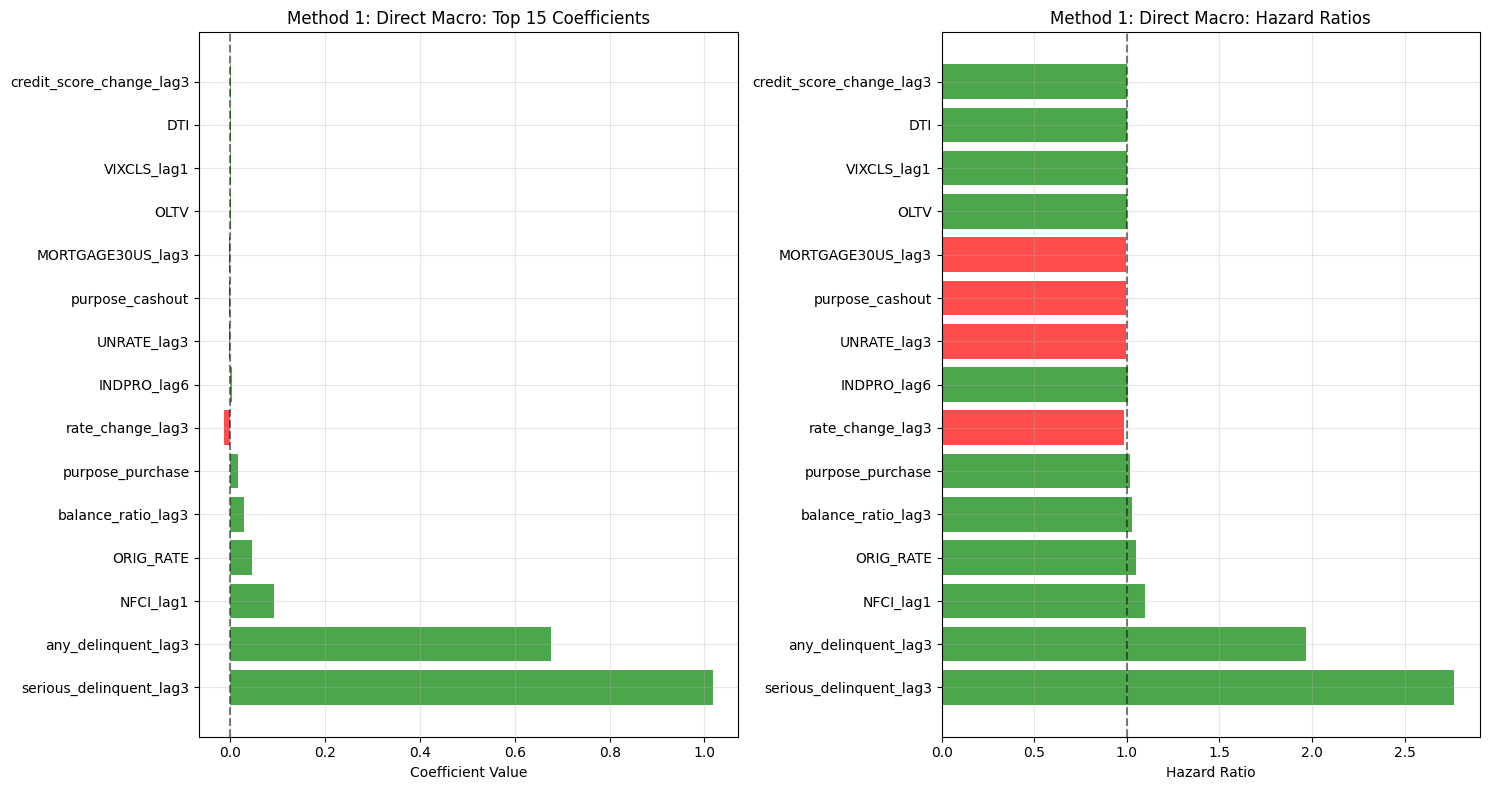

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p),abs_coef,hazard_ratio
covariate,,,,,,,,,,,,,
serious_delinquent_lag3,1.018075,2.767861,0.037946,0.943702,1.092447,2.569476,2.981562,0.0,26.829629,1.458291e-158,524.320360,1.018075,2.767861
any_delinquent_lag3,0.676289,1.966565,0.027265,0.622849,0.729728,1.864232,2.074515,0.0,24.803950,8.127069e-136,448.759486,0.676289,1.966565
NFCI_lag1,0.092162,1.096542,0.024944,0.043273,0.141050,1.044223,1.151483,0.0,3.694789,2.200696e-04,12.149753,0.092162,1.096542
ORIG_RATE,0.046445,1.047541,0.007970,0.030824,0.062067,1.031304,1.064034,0.0,5.827293,5.633363e-09,27.403356,0.046445,1.047541
balance_ratio_lag3,0.027665,1.028051,0.018971,-0.009517,0.064848,0.990528,1.066996,0.0,1.458281,1.447630e-01,2.788235,0.027665,1.028051
purpose_purchase,0.015890,1.016017,0.009839,-0.003394,0.035174,0.996612,1.035800,0.0,1.615014,1.063077e-01,3.233682,0.015890,1.016017
rate_change_lag3,-0.014424,0.985679,0.040664,-0.094124,0.065276,0.910170,1.067453,0.0,-0.354718,7.228007e-01,0.468330,0.014424,0.985679
INDPRO_lag6,0.004195,1.004204,0.001261,0.001724,0.006667,1.001725,1.006689,0.0,3.326758,8.786257e-04,10.152464,0.004195,1.004204
UNRATE_lag3,-0.003880,0.996128,0.001989,-0.007778,0.000018,0.992253,1.000018,0.0,-1.950823,5.107808e-02,4.291152,0.003880,0.996128


In [ ]:
import pandas as pd
import numpy as np
from lifelines import CoxTimeVaryingFitter
from lifelines.utils import concordance_index
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
def train_cox_model(train_data, method_name="Cox Model", penalizer=0.01):
    """Train Cox time-varying model"""
    from lifelines import CoxTimeVaryingFitter

    print(f"🚀 Training {method_name}...")

    # Convert polars to pandas if needed
    if hasattr(train_data, 'to_pandas'):
        train_df = train_data.to_pandas()
    else:
        train_df = train_data.copy()

    # Initialize model with regularization
    ctv = CoxTimeVaryingFitter(penalizer=penalizer)

    # Train the model
    try:
        ctv.fit(train_df,
                id_col='LOAN_ID',
                start_col='start',
                stop_col='stop',
                event_col='event',
                show_progress=True)

        print(f"   ✅ {method_name} training completed successfully")
        print(f"   📊 Log-likelihood: {ctv.log_likelihood_:.3f}")

        n_params = len(ctv.params_)
        aic = 2 * n_params - 2 * ctv.log_likelihood_
        print(f"   📊 AIC: {aic:.3f}")
        ctv._aic = aic  # Store for later use

        return ctv

    except Exception as e:
        print(f"   ❌ Training failed: {e}")
        return None

def evaluate_cox_model_fixed(model, test_data, method_name="Cox Model"):
    print(f"📊 Evaluating {method_name}...")

    # Convert polars to pandas if needed
    if hasattr(test_data, 'to_pandas'):
        test_df = test_data.to_pandas()
    else:
        test_df = test_data.copy()

    try:
        # 1. Calculate Concordance Index
        # Get one prediction per loan (use last observation)
        loan_predictions = test_df.groupby('LOAN_ID').last()
        risk_scores = model.predict_partial_hazard(loan_predictions)

        # Create survival arrays for concordance calculation
        events = test_df.groupby('LOAN_ID')['event'].max().values
        durations = test_df.groupby('LOAN_ID')['stop'].max().values

        # Calculate concordance index using lifelines function
        c_index = concordance_index(durations, -risk_scores, events)  # negative because higher risk = lower survival
        print(f"   📈 C-Index: {c_index:.4f}")

        # 2. Get unique loan-level data for survival predictions
        test_loans = test_df.groupby('LOAN_ID').agg({
            'stop': 'max',  # Last observed time
            'event': 'max',  # Whether ever defaulted
            'start': 'min'   # First observation time
        }).reset_index()

        # Get final observation for each loan (for covariates)
        final_obs = test_df.loc[test_df.groupby('LOAN_ID')['stop'].idxmax()].copy()

        # 3. Time-dependent AUC at specific time points - FIXED VERSION
        time_points = [12, 24, 36]  # months
        auc_scores = {}

        for t in time_points:
            try:
                # Method 1: Use hazard ratio as risk score
                risk_scores = model.predict_partial_hazard(final_obs)

                # Create binary outcome: defaulted by time t
                outcomes = (test_loans['stop'] <= t) & (test_loans['event'] == 1)

                # Only calculate AUC if we have both classes and reasonable sample size
                if outcomes.sum() >= 5 and (~outcomes).sum() >= 5:  # At least 5 in each class
                    from sklearn.metrics import roc_auc_score
                    auc = roc_auc_score(outcomes, risk_scores)
                    auc_scores[f'AUC_{t}mo'] = auc
                    print(f"   📈 AUC at {t} months: {auc:.4f} (events: {outcomes.sum()}/{len(outcomes)})")
                else:
                    auc_scores[f'AUC_{t}mo'] = np.nan
                    print(f"   ⚠️ AUC at {t} months: insufficient events ({outcomes.sum()}/{len(outcomes)})")

            except Exception as e:
                print(f"   ⚠️ AUC at {t} months failed: {e}")
                auc_scores[f'AUC_{t}mo'] = np.nan
        brier_scores = {}
        for t in time_points:
            try:
                # Simple approach: predict risk and compare to actual outcomes at time t
                risk_scores = model.predict_partial_hazard(final_obs)
                # Normalize risk scores to probabilities (approximate)
                risk_probs = risk_scores / (1 + risk_scores)  # Rough approximation

                # Actual outcomes at time t
                actual = ((test_loans['stop'] <= t) & (test_loans['event'] == 1)).astype(int)

                # Brier score: mean squared error between predicted prob and actual outcome
                brier = np.mean((risk_probs - actual) ** 2)
                brier_scores[f'Brier_{t}mo'] = brier
                print(f"   📊 Brier Score at {t} months: {brier:.4f} (lower is better)")

            except Exception as e:
                brier_scores[f'Brier_{t}mo'] = np.nan

        # 5. Model coefficients summary (top 10 by absolute value)
        coef_summary = model.summary.copy()
        coef_summary['abs_coef'] = np.abs(coef_summary['coef'])
        top_coefs = coef_summary.nlargest(10, 'abs_coef')[['coef', 'p']]

        print(f"\n   🔍 Top 10 Coefficients by Magnitude:")
        for var, row in top_coefs.iterrows():
            significance = "***" if row['p'] < 0.001 else ("**" if row['p'] < 0.01 else ("*" if row['p'] < 0.05 else ""))
            hazard_ratio = np.exp(row['coef'])
            print(f"     {var:<25}: {row['coef']:>8.4f} (HR: {hazard_ratio:>6.3f}) {significance}")

        # 6. Model diagnostics
        print(f"\n   🔧 Model Diagnostics:")
        print(f"     Convergence: {'✅ Yes' if model.summary.shape[0] > 0 else '❌ No'}")
        print(f"     Parameters: {len(model.params_)}")
        print(f"     Log-likelihood: {model.log_likelihood_:.3f}")

        # Return results dictionary
        results = {
            'method': method_name,
            'c_index': c_index,
            'log_likelihood': model.log_likelihood_,
            'AIC': getattr(model, '_aic', 2 * len(model.params_) - 2 * model.log_likelihood_),
            **auc_scores,
            **brier_scores,
            'n_test_loans': len(test_loans),
            'n_test_events': test_loans['event'].sum(),
            'n_parameters': len(model.params_),
            'model_object': model
        }

        return results

    except Exception as e:
        print(f"   ❌ Evaluation failed: {e}")
        return {'method': method_name, 'error': str(e)}

def plot_coefficient_importance(model, method_name="Cox Model", top_n=15):
    """
    Plot coefficient importance with hazard ratios
    """
    coef_summary = model.summary.copy()
    coef_summary['abs_coef'] = np.abs(coef_summary['coef'])
    coef_summary['hazard_ratio'] = np.exp(coef_summary['coef'])

    # Get top coefficients
    top_coefs = coef_summary.nlargest(top_n, 'abs_coef')

    # Create plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 8))

    # Plot 1: Coefficients
    colors = ['red' if x < 0 else 'green' for x in top_coefs['coef']]
    ax1.barh(range(len(top_coefs)), top_coefs['coef'], color=colors, alpha=0.7)
    ax1.set_yticks(range(len(top_coefs)))
    ax1.set_yticklabels(top_coefs.index, fontsize=10)
    ax1.set_xlabel('Coefficient Value')
    ax1.set_title(f'{method_name}: Top {top_n} Coefficients')
    ax1.axvline(x=0, color='black', linestyle='--', alpha=0.5)
    ax1.grid(True, alpha=0.3)

    # Plot 2: Hazard Ratios
    colors = ['red' if x < 1 else 'green' for x in top_coefs['hazard_ratio']]
    ax2.barh(range(len(top_coefs)), top_coefs['hazard_ratio'], color=colors, alpha=0.7)
    ax2.set_yticks(range(len(top_coefs)))
    ax2.set_yticklabels(top_coefs.index, fontsize=10)
    ax2.set_xlabel('Hazard Ratio')
    ax2.set_title(f'{method_name}: Hazard Ratios')
    ax2.axvline(x=1, color='black', linestyle='--', alpha=0.5)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return top_coefs

# Updated usage:
model1 = train_cox_model(train_start_stop, "Method 1", penalizer=0.01)
results1_fixed = evaluate_cox_model_fixed(model1, test_start_stop, "Method 1: Direct Macro")
plot_coefficient_importance(model1, "Method 1: Direct Macro")

In [ ]:
results1_fixed

{'method': 'Method 1: Direct Macro',
 'c_index': np.float64(0.8384069434625808),
 'log_likelihood': np.float64(-23745.88831638112),
 'AIC': np.float64(47527.77663276224),
 'AUC_12mo': nan,
 'AUC_24mo': np.float64(0.9529669645540583),
 'AUC_36mo': np.float64(0.8931881130909751),
 'Brier_12mo': np.float64(0.24943465842839466),
 'Brier_24mo': np.float64(0.2487630076590431),
 'Brier_36mo': np.float64(0.2469480420085293),
 'n_test_loans': 46638,
 'n_test_events': np.int64(937),
 'n_parameters': 18,
 'model_object': <lifelines.CoxTimeVaryingFitter: fitted with 4007203 periods, 108832 subjects, 2185 events>}

In [ ]:
train_start_stop_pca = train_data.with_columns([
    # Create start column (current time period)
    pl.col("time").alias("start"),

    # Create stop column (time + 1)
    (pl.col("time") + 1).alias("stop")
]).select([
    # Keep essential columns in proper order
    "LOAN_ID",
    "start",
    "stop",
    "event",

    # Your selected variables
    "balance_ratio_lag3",
    "credit_score_change_lag3",
    "any_delinquent_lag3",
    "serious_delinquent_lag3",
    "rate_change_lag3",
    "payment_to_income_lag3",

    # Origination characteristics
    "CSCORE_B",
    "DTI",
    "OLTV",
    "ORIG_RATE",
    "PURPOSE",

    # Macro lags
    'DFF_lag1',
    'VIXCLS_lag1',
    'NFCI_lag1',
    'STLFSI4_lag1',
    'DEXUSEU_lag1',
    'DGS3MO_lag3',
    'DGS2_lag3',
    'DGS10_lag3',
    'DAAA_lag3',
    'DBAA_lag3',
    'BAMLH0A0HYM2_lag3',
    'MORTGAGE30US_lag3',
    'DFEDTARU_lag3',
    'NASDAQCOM_lag3',
    'UNRATE_lag3',
    'UNRATE_lag6',
    'PAYEMS_lag3',
    'PAYEMS_lag6',
    'CPIAUCSL_lag3',
    'CPIAUCSL_lag6',
    'CPILFESL_lag3',
    'CPILFESL_lag6',
    'PCEPI_lag3',
    'PCEPI_lag6',
    'INDPRO_lag6',
    'INDPRO_lag12',
    'DSPIC96_lag6',
    'DSPIC96_lag12',
    'PSAVERT_lag6',
    'PSAVERT_lag12',
    'CSUSHPISA_lag6',
    'CSUSHPISA_lag12',
    'AHETPI_lag6',
    'CIVPART_lag6',
    'RRSFS_lag6',
    'COMPUTSA_lag6',
    'HOUST_lag6'

])

print("\nStart-stop format sample:")
print(test_start_stop_pca.select(["LOAN_ID", "start", "stop", "event"]).head())

print(f"\nDataset shape: {test_start_stop_pca.shape}")
print(f"Unique loans: {test_start_stop_pca['LOAN_ID'].n_unique():,}")

# Check for any issues
print(f"\nData validation:")
print(f"Any negative intervals: {(test_start_stop_pca['stop'] <= test_start_stop_pca['start']).sum()}")
print(f"Missing values check:")
null_counts = test_start_stop_pca.null_count()
print(null_counts.select([col for col in null_counts.columns if null_counts[col].item() > 0]))

# Export for Cox regression
# df_start_stop.write_parquet("loan_data_start_stop.parquet")
# df_start_stop.write_csv("loan_data_start_stop.csv")

print("\nReady for Cox regression with time-varying covariates!")
print("Use with lifelines.CoxTimeVaryingFitter:")
print("ctv = CoxTimeVaryingFitter()")
print("ctv.fit(df, id_col='LOAN_ID', start_col='start', stop_col='stop', event_col='event')")


Start-stop format sample:
shape: (5, 4)
┌──────────────┬───────┬──────┬───────┐
│ LOAN_ID      ┆ start ┆ stop ┆ event │
│ ---          ┆ ---   ┆ ---  ┆ ---   │
│ str          ┆ f64   ┆ f64  ┆ i8    │
╞══════════════╪═══════╪══════╪═══════╡
│ 468862729156 ┆ 30.0  ┆ 31.0 ┆ 0     │
│ 645367971913 ┆ 90.0  ┆ 91.0 ┆ 0     │
│ 892289882024 ┆ 29.0  ┆ 30.0 ┆ 0     │
│ 453897293099 ┆ 33.0  ┆ 34.0 ┆ 0     │
│ 145483153606 ┆ 74.0  ┆ 75.0 ┆ 0     │
└──────────────┴───────┴──────┴───────┘

Dataset shape: (1710973, 52)
Unique loans: 46,860

Data validation:
Any negative intervals: 0
Missing values check:
shape: (1, 6)
┌────────────────┬────────────────┬────────────────┬───────────────┬───────────────┬───────────────┐
│ balance_ratio_ ┆ credit_score_c ┆ any_delinquent ┆ serious_delin ┆ rate_change_l ┆ payment_to_in │
│ lag3           ┆ hange_lag3     ┆ _lag3          ┆ quent_lag3    ┆ ag3           ┆ come_lag3     │
│ ---            ┆ ---            ┆ ---            ┆ ---           ┆ ---           ┆ 

In [ ]:
train_start_stop_pca

LOAN_ID,start,stop,event,balance_ratio_lag3,credit_score_change_lag3,any_delinquent_lag3,serious_delinquent_lag3,rate_change_lag3,payment_to_income_lag3,CSCORE_B,DTI,OLTV,ORIG_RATE,PURPOSE,DFF_lag1,VIXCLS_lag1,NFCI_lag1,STLFSI4_lag1,DEXUSEU_lag1,DGS3MO_lag3,DGS2_lag3,DGS10_lag3,DAAA_lag3,DBAA_lag3,BAMLH0A0HYM2_lag3,MORTGAGE30US_lag3,DFEDTARU_lag3,NASDAQCOM_lag3,UNRATE_lag3,UNRATE_lag6,PAYEMS_lag3,PAYEMS_lag6,CPIAUCSL_lag3,CPIAUCSL_lag6,CPILFESL_lag3,CPILFESL_lag6,PCEPI_lag3,PCEPI_lag6,INDPRO_lag6,INDPRO_lag12,DSPIC96_lag6,DSPIC96_lag12,PSAVERT_lag6,PSAVERT_lag12,CSUSHPISA_lag6,CSUSHPISA_lag12,AHETPI_lag6,CIVPART_lag6,RRSFS_lag6,COMPUTSA_lag6,HOUST_lag6
str,f64,f64,i8,f64,f64,i8,i8,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""325308298388""",33.0,34.0,0,0.955839,-727.0,0,0,0.0,2.077911,727.0,46.0,75.0,4.25,"""P""",2.4,13.31,-0.5784,-0.4647,1.1211,2.4,2.21,2.4,3.67,4.63,4.06,4.07,2.5,7804.821,3.6,3.8,150621.0,150065.0,255.296,253.319,262.217,261.186,103.435,102.836,102.8251,104.0585,15560.4,15238.6,8.5,6.6,206.849,203.641,23.19,63.1,194123.0,1304.0,1121.0
"""745658465788""",25.0,26.0,0,0.852171,-793.0,0,0,0.0,2.367143,793.0,36.0,93.0,3.375,"""R""",2.4,19.57,-0.47142,-0.0467,1.1418,2.37,2.86,3.12,4.22,5.22,4.02,4.87,2.25,7236.081,3.8,3.8,149617.0,149279.0,252.594,251.663,259.439,257.891,102.63,102.208,104.0585,101.7319,15238.6,14921.1,6.6,5.8,203.641,199.219,22.78,62.6,196074.0,1262.0,1288.0
"""986941713659""",20.0,21.0,0,0.972429,-721.0,0,0,0.0,2.315307,721.0,42.0,91.0,3.75,"""R""",2.19,19.35,-0.57289,-0.4867,1.1488,2.07,2.64,2.89,3.88,4.77,3.45,4.55,2.0,7892.233,3.8,3.8,149279.0,148740.0,251.663,250.792,257.891,257.145,102.208,101.941,102.381,101.2493,15057.8,14771.1,6.0,5.6,201.401,195.922,22.6,62.9,196163.0,1262.0,1357.0
"""637898871606""",42.0,43.0,0,0.941638,-730.0,0,0,0.0,2.414457,730.0,39.0,77.0,4.625,"""C""",0.1,22.89,-0.50335,-0.2053,1.1831,0.16,0.19,0.73,2.44,3.64,6.07,3.16,0.25,9839.97,11.0,4.4,137671.0,150895.0,257.042,258.076,265.849,267.054,104.233,104.252,97.606,102.4601,15704.9,15697.5,12.4,7.0,216.439,210.817,24.13,62.6,181467.0,1237.0,1266.0
"""987615273563""",18.0,19.0,0,0.969429,-760.0,0,0,0.0,2.154287,760.0,45.0,90.0,4.625,"""P""",1.82,13.68,-0.55308,-0.2035,1.1679,1.79,2.38,2.87,3.85,4.67,3.47,4.47,1.75,7084.142,4.0,4.0,148422.0,147660.0,250.227,248.859,256.63,255.204,101.766,101.199,101.4852,100.0865,14886.6,14660.2,5.7,6.0,198.287,191.436,22.36,62.7,193448.0,1208.0,1299.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""000126055895""",15.0,16.0,0,0.980225,-701.0,0,0,0.0,4.667737,701.0,21.0,53.0,3.075,"""R""",0.09,25.0,-0.54548,-0.2798,1.1826,0.11,0.13,0.68,2.31,3.36,5.26,2.89,0.25,11088.74,7.8,11.0,141770.0,137671.0,259.997,257.042,268.933,265.849,105.046,104.233,91.6745,101.9421,17047.5,15683.8,18.4,6.2,217.47,213.939,24.78,61.5,201538.0,1229.0,1266.0
"""000126055895""",40.0,41.0,0,0.935143,-701.0,0,0,0.0,4.453061,701.0,21.0,53.0,3.075,"""R""",4.1,21.78,-0.20148,-0.0103,1.0591,3.87,4.38,3.98,5.1,6.26,5.0,6.9,3.25,10801.494,3.6,3.5,153913.0,153049.0,297.979,294.94,299.381,295.08,117.891,116.662,103.0505,101.2146,16219.1,16143.2,3.1,3.6,303.109,286.298,27.66,62.1,223622.0,1421.0,1381.0
"""000126055895""",27.0,28.0,0,0.958945,-701.0,0,0,0.0,4.566406,701.0,21.0,53.0,3.075,"""R""",0.08,18.5,-0.57694,-0.6643,1.1416,0.04,0.24,1.37,2.53,3.23,3.12,2.9,0.25,15023.539,4.7,5.9,147712.0,145828.0,273.942,270.71,279.727,277.608,110.047,108.748,99.6483,98.2039,16757.8,16391.2,8.4,11.8,258.036,236.58,25.81,61.7,226054.0,1280.0,1650.0


In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def add_pca_macro_variables(train_start_stop, test_start_stop, n_components=0.95):
    """
    Simple PCA on macro variables, join back to start-stop data
    """
    print("🔄 Applying PCA to macro variables...")

    # Define macro columns
    macro_cols = [ 'DFF_lag1',
    'VIXCLS_lag1',
    'NFCI_lag1',
    'STLFSI4_lag1',
    'DEXUSEU_lag1',
    'DGS3MO_lag3',
    'DGS2_lag3',
    'DGS10_lag3',
    'DAAA_lag3',
    'DBAA_lag3',
    'BAMLH0A0HYM2_lag3',
    'MORTGAGE30US_lag3',
    'DFEDTARU_lag3',
    'NASDAQCOM_lag3',
    'UNRATE_lag3',
    'UNRATE_lag6',
    'PAYEMS_lag3',
    'PAYEMS_lag6',
    'CPIAUCSL_lag3',
    'CPIAUCSL_lag6',
    'CPILFESL_lag3',
    'CPILFESL_lag6',
    'PCEPI_lag3',
    'PCEPI_lag6',
    'INDPRO_lag6',
    'INDPRO_lag12',
    'DSPIC96_lag6',
    'DSPIC96_lag12',
    'PSAVERT_lag6',
    'PSAVERT_lag12',
    'CSUSHPISA_lag6',
    'CSUSHPISA_lag12',
    'AHETPI_lag6',
    'CIVPART_lag6',
    'RRSFS_lag6',
    'COMPUTSA_lag6',
    'HOUST_lag6']

    # Convert to pandas and extract macro data
    train_df = train_start_stop.to_pandas() if hasattr(train_start_stop, 'to_pandas') else train_start_stop
    test_df = test_start_stop.to_pandas() if hasattr(test_start_stop, 'to_pandas') else test_start_stop

    train_macro = train_df[macro_cols]
    test_macro = test_df[macro_cols]

    # Fit PCA on training data
    scaler = StandardScaler()
    pca = PCA(n_components=n_components)

    train_macro_scaled = scaler.fit_transform(train_macro)
    train_pca = pca.fit_transform(train_macro_scaled)

    # Transform test data with same scaler/PCA
    test_macro_scaled = scaler.transform(test_macro)
    test_pca = pca.transform(test_macro_scaled)

    print(f"   📊 Reduced {len(macro_cols)} macro vars to {train_pca.shape[1]} PCA components")
    print(f"   📈 Explained variance: {pca.explained_variance_ratio_.sum():.3f}")

    # Create PCA component names
    pca_names = [f'PC{i+1}_macro' for i in range(train_pca.shape[1])]

    # Add PCA components to dataframes
    train_pca_df = pd.DataFrame(train_pca, columns=pca_names, index=train_df.index)
    test_pca_df = pd.DataFrame(test_pca, columns=pca_names, index=test_df.index)

    # Join back to original data (drop original macro vars)
    train_with_pca = train_df.drop(columns=macro_cols).join(train_pca_df)
    test_with_pca = test_df.drop(columns=macro_cols).join(test_pca_df)

    print(f"   ✅ PCA completed. New shape: {train_with_pca.shape}")

    return train_with_pca, test_with_pca

# Usage:
print("🚀 PCA + Cox Pipeline")

# Step 1: Apply PCA
train_pca, test_pca = add_pca_macro_variables(train_start_stop_pca, test_start_stop_pca)



🚀 PCA + Cox Pipeline
🔄 Applying PCA to macro variables...
   📊 Reduced 37 macro vars to 7 PCA components
   📈 Explained variance: 0.953
   ✅ PCA completed. New shape: (4008786, 22)


In [ ]:
train_pca.columns

Index(['LOAN_ID', 'start', 'stop', 'event', 'balance_ratio_lag3',
       'credit_score_change_lag3', 'any_delinquent_lag3',
       'serious_delinquent_lag3', 'rate_change_lag3', 'payment_to_income_lag3',
       'CSCORE_B', 'DTI', 'OLTV', 'ORIG_RATE', 'PURPOSE', 'PC1_macro',
       'PC2_macro', 'PC3_macro', 'PC4_macro', 'PC5_macro', 'PC6_macro',
       'PC7_macro'],
      dtype='object')

In [ ]:
train_pca = pl.from_pandas(train_pca)
train_pca = train_pca.with_columns([
    (pl.col('PURPOSE') == 'P').cast(pl.Int8).alias('purpose_purchase'),
    (pl.col('PURPOSE') == 'C').cast(pl.Int8).alias('purpose_cashout'),
    # Refinance ('R') becomes the reference category
])
train_pca = train_pca.drop('PURPOSE')
train_pca = train_pca.to_pandas()
test_pca = pl.from_pandas(test_pca)
test_pca = test_pca.with_columns([
    (pl.col('PURPOSE') == 'P').cast(pl.Int8).alias('purpose_purchase'),
    (pl.col('PURPOSE') == 'C').cast(pl.Int8).alias('purpose_cashout'),
    # Refinance ('R') becomes the reference category
])
test_pca = test_pca.drop('PURPOSE')
test_pca = test_pca.to_pandas()
train_pca = train_pca[train_pca["balance_ratio_lag3"].notna()]
test_pca = test_pca[test_pca["balance_ratio_lag3"].notna()]

In [ ]:
train_pca

,LOAN_ID,start,stop,event,balance_ratio_lag3,credit_score_change_lag3,any_delinquent_lag3,serious_delinquent_lag3,rate_change_lag3,payment_to_income_lag3,...,ORIG_RATE,PC1_macro,PC2_macro,PC3_macro,PC4_macro,PC5_macro,PC6_macro,PC7_macro,purpose_purchase,purpose_cashout
0,325308298388,33.0,34.0,0,0.955839,-727.0,0.0,0.0,0.0,2.077911,...,4.250,-1.235726,2.896310,-1.181239,-0.157806,-0.011539,0.953229,0.356772,1,0
1,745658465788,25.0,26.0,0,0.852171,-793.0,0.0,0.0,0.0,2.367143,...,3.375,-1.068877,3.265589,-0.684130,0.105143,-0.288750,-0.882563,0.005212,0,0
2,986941713659,20.0,21.0,0,0.972429,-721.0,0.0,0.0,0.0,2.315307,...,3.750,-1.606538,2.988881,-1.063929,0.615263,-0.104832,-0.502116,-0.002976,0,0
3,637898871606,42.0,43.0,0,0.941638,-730.0,0.0,0.0,0.0,2.414457,...,4.625,-4.153910,-0.587272,1.129804,-1.748127,2.373680,0.267005,1.057179,0,1
4,987615273563,18.0,19.0,0,0.969429,-760.0,0.0,0.0,0.0,2.154287,...,4.625,-2.310302,3.049192,-1.403649,0.565870,-0.189299,-0.868263,-0.089738,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4007198,000126055895,15.0,16.0,0,0.980225,-701.0,0.0,0.0,0.0,4.667737,...,3.075,-4.590865,-3.339641,-0.503315,-2.883774,-0.366876,0.343431,-0.774681,0,0
4007199,000126055895,40.0,41.0,0,0.935143,-701.0,0.0,0.0,0.0,4.453061,...,3.075,6.183416,0.528563,0.662213,-0.889132,0.032090,-1.556956,-0.933393,0,0
4007200,000126055895,27.0,28.0,0,0.958945,-701.0,0.0,0.0,0.0,4.566406,...,3.075,-1.068084,-3.513443,-0.136871,2.059656,0.013502,0.961163,-0.967677,0,0
4007201,000126055895,33.0,34.0,0,0.948058,-701.0,0.0,0.0,0.0,4.514561,...,3.075,1.864829,-2.244009,2.270706,1.446168,-0.570711,0.028643,-1.416281,0,0


In [ ]:
def train_cox_model(train_data, method_name="Cox Model", penalizer=0.01):
    """Train Cox time-varying model"""
    from lifelines import CoxTimeVaryingFitter

    print(f"🚀 Training {method_name}...")

    # Convert polars to pandas if needed
    if hasattr(train_data, 'to_pandas'):
        train_df = train_data.to_pandas()
    else:
        train_df = train_data.copy()

    # Initialize model with regularization
    ctv = CoxTimeVaryingFitter(penalizer=penalizer)

    # Train the model
    try:
        ctv.fit(train_df,
                id_col='LOAN_ID',
                start_col='start',
                stop_col='stop',
                event_col='event',
                show_progress=True)

        print(f"   ✅ {method_name} training completed successfully")
        print(f"   📊 Log-likelihood: {ctv.log_likelihood_:.3f}")

        n_params = len(ctv.params_)
        aic = 2 * n_params - 2 * ctv.log_likelihood_
        print(f"   📊 AIC: {aic:.3f}")
        ctv._aic = aic  # Store for later use

        return ctv

    except Exception as e:
        print(f"   ❌ Training failed: {e}")
        return None

def evaluate_cox_model_fixed(model, test_data, method_name="Cox Model"):
    """Comprehensive evaluation of Cox model"""
    from lifelines.utils import concordance_index
    from sklearn.metrics import roc_auc_score

    print(f"📊 Evaluating {method_name}...")

    # Convert polars to pandas if needed
    if hasattr(test_data, 'to_pandas'):
        test_df = test_data.to_pandas()
    else:
        test_df = test_data.copy()

    try:
        # 1. Calculate Concordance Index
        loan_predictions = test_df.groupby('LOAN_ID').last()
        risk_scores = model.predict_partial_hazard(loan_predictions)

        events = test_df.groupby('LOAN_ID')['event'].max().values
        durations = test_df.groupby('LOAN_ID')['stop'].max().values

        c_index = concordance_index(durations, -risk_scores, events)
        print(f"   📈 C-Index: {c_index:.4f}")

        # 2. Time-dependent AUC
        test_loans = test_df.groupby('LOAN_ID').agg({
            'stop': 'max', 'event': 'max', 'start': 'min'
        }).reset_index()

        final_obs = test_df.loc[test_df.groupby('LOAN_ID')['stop'].idxmax()].copy()

        time_points = [12, 24, 36]
        auc_scores = {}

        for t in time_points:
            try:
                risk_scores = model.predict_partial_hazard(final_obs)
                outcomes = (test_loans['stop'] <= t) & (test_loans['event'] == 1)

                if outcomes.sum() >= 5 and (~outcomes).sum() >= 5:
                    auc = roc_auc_score(outcomes, risk_scores)
                    auc_scores[f'AUC_{t}mo'] = auc
                    print(f"   📈 AUC at {t} months: {auc:.4f}")
                else:
                    auc_scores[f'AUC_{t}mo'] = np.nan
                    print(f"   ⚠️ AUC at {t} months: insufficient events")

            except Exception as e:
                auc_scores[f'AUC_{t}mo'] = np.nan

        # 3. Top coefficients
        coef_summary = model.summary.copy()
        coef_summary['abs_coef'] = np.abs(coef_summary['coef'])
        top_coefs = coef_summary.nlargest(10, 'abs_coef')[['coef', 'p']]

        print(f"\n   🔍 Top 10 Coefficients:")
        for var, row in top_coefs.iterrows():
            significance = "***" if row['p'] < 0.001 else ("**" if row['p'] < 0.01 else ("*" if row['p'] < 0.05 else ""))
            print(f"     {var:<25}: {row['coef']:>8.4f} {significance}")

        # Return results
        results = {
            'method': method_name,
            'c_index': c_index,
            'log_likelihood': model.log_likelihood_,
            'AIC': getattr(model, '_aic', 2 * len(model.params_) - 2 * model.log_likelihood_),
            **auc_scores,
            'n_test_loans': len(test_loans),
            'n_test_events': test_loans['event'].sum(),
            'model_object': model
        }

        return results

    except Exception as e:
        print(f"   ❌ Evaluation failed: {e}")
        return {'method': method_name, 'error': str(e)}

def compare_methods(results_list):
    """Compare multiple methods"""
    print("\n" + "="*80)
    print("🏆 METHOD COMPARISON")
    print("="*80)

    comparison_df = pd.DataFrame(results_list)

    print(f"{'Method':<25} {'C-Index':<10} {'AUC@12mo':<10} {'AUC@24mo':<10} {'AUC@36mo':<10} {'AIC':<10}")
    print("-" * 80)

    for _, row in comparison_df.iterrows():
        method = row['method'][:24]
        c_idx = f"{row.get('c_index', np.nan):.4f}" if not pd.isna(row.get('c_index')) else "N/A"
        auc_12 = f"{row.get('AUC_12mo', np.nan):.4f}" if not pd.isna(row.get('AUC_12mo')) else "N/A"
        auc_24 = f"{row.get('AUC_24mo', np.nan):.4f}" if not pd.isna(row.get('AUC_24mo')) else "N/A"
        auc_36 = f"{row.get('AUC_36mo', np.nan):.4f}" if not pd.isna(row.get('AUC_36mo')) else "N/A"
        aic = f"{row.get('AIC', np.nan):.1f}" if not pd.isna(row.get('AIC')) else "N/A"

        print(f"{method:<25} {c_idx:<10} {auc_12:<10} {auc_24:<10} {auc_36:<10} {aic:<10}")

    print("="*80)

    if 'c_index' in comparison_df.columns:
        best_method = comparison_df.loc[comparison_df['c_index'].idxmax(), 'method']
        best_c_index = comparison_df['c_index'].max()
        print(f"🥇 Best: {best_method} (C-Index: {best_c_index:.4f})")

    return comparison_df

# Usage:
print("🚀 Complete PCA + Cox Pipeline")



# Step 2: Train Cox model with PCA
model_pca = train_cox_model(train_pca, "Method 2: PCA Macro", penalizer=0.01)

# Step 3: Evaluate PCA model
if model_pca:
    results_pca = evaluate_cox_model_fixed(model_pca, test_pca, "Method 2: PCA Macro")

# Step 4: Compare with original
# all_results = [results1, results_pca]  # Add your original results
# comparison = compare_methods(all_results)

🚀 Complete PCA + Cox Pipeline
🚀 Training Method 2: PCA Macro...
Iteration 1: norm_delta = 1.95e-01, step_size = 0.9500, log_lik = -24598.00468, newton_decrement = 9.40e+02, seconds_since_start = 2.5
Iteration 2: norm_delta = 1.32e-02, step_size = 0.9500, log_lik = -23726.84085, newton_decrement = 5.95e+00, seconds_since_start = 4.9
Iteration 3: norm_delta = 9.08e-04, step_size = 0.9500, log_lik = -23720.83978, newton_decrement = 2.73e-02, seconds_since_start = 7.3
Iteration 4: norm_delta = 4.90e-05, step_size = 1.0000, log_lik = -23720.81252, newton_decrement = 7.16e-05, seconds_since_start = 9.7
Iteration 5: norm_delta = 3.21e-09, step_size = 1.0000, log_lik = -23720.81244, newton_decrement = 3.10e-13, seconds_since_start = 12.1
Convergence completed after 5 iterations.
   ✅ Method 2: PCA Macro training completed successfully
   📊 Log-likelihood: -23720.812
   📊 AIC: 47479.625
📊 Evaluating Method 2: PCA Macro...
   📈 C-Index: 0.8359
   ⚠️ AUC at 12 months: insufficient events
   📈 AUC

In [ ]:
train_start_stop_pca

LOAN_ID,start,stop,event,balance_ratio_lag3,credit_score_change_lag3,any_delinquent_lag3,serious_delinquent_lag3,rate_change_lag3,payment_to_income_lag3,CSCORE_B,DTI,OLTV,ORIG_RATE,PURPOSE,DFF_lag1,VIXCLS_lag1,NFCI_lag1,STLFSI4_lag1,DEXUSEU_lag1,DGS3MO_lag3,DGS2_lag3,DGS10_lag3,DAAA_lag3,DBAA_lag3,BAMLH0A0HYM2_lag3,MORTGAGE30US_lag3,DFEDTARU_lag3,NASDAQCOM_lag3,UNRATE_lag3,UNRATE_lag6,PAYEMS_lag3,PAYEMS_lag6,CPIAUCSL_lag3,CPIAUCSL_lag6,CPILFESL_lag3,CPILFESL_lag6,PCEPI_lag3,PCEPI_lag6,INDPRO_lag6,INDPRO_lag12,DSPIC96_lag6,DSPIC96_lag12,PSAVERT_lag6,PSAVERT_lag12,CSUSHPISA_lag6,CSUSHPISA_lag12,AHETPI_lag6,CIVPART_lag6,RRSFS_lag6,COMPUTSA_lag6,HOUST_lag6
str,f64,f64,i8,f64,f64,i8,i8,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""325308298388""",33.0,34.0,0,0.955839,-727.0,0,0,0.0,2.077911,727.0,46.0,75.0,4.25,"""P""",2.4,13.31,-0.5784,-0.4647,1.1211,2.4,2.21,2.4,3.67,4.63,4.06,4.07,2.5,7804.821,3.6,3.8,150621.0,150065.0,255.296,253.319,262.217,261.186,103.435,102.836,102.8251,104.0585,15560.4,15238.6,8.5,6.6,206.849,203.641,23.19,63.1,194123.0,1304.0,1121.0
"""745658465788""",25.0,26.0,0,0.852171,-793.0,0,0,0.0,2.367143,793.0,36.0,93.0,3.375,"""R""",2.4,19.57,-0.47142,-0.0467,1.1418,2.37,2.86,3.12,4.22,5.22,4.02,4.87,2.25,7236.081,3.8,3.8,149617.0,149279.0,252.594,251.663,259.439,257.891,102.63,102.208,104.0585,101.7319,15238.6,14921.1,6.6,5.8,203.641,199.219,22.78,62.6,196074.0,1262.0,1288.0
"""986941713659""",20.0,21.0,0,0.972429,-721.0,0,0,0.0,2.315307,721.0,42.0,91.0,3.75,"""R""",2.19,19.35,-0.57289,-0.4867,1.1488,2.07,2.64,2.89,3.88,4.77,3.45,4.55,2.0,7892.233,3.8,3.8,149279.0,148740.0,251.663,250.792,257.891,257.145,102.208,101.941,102.381,101.2493,15057.8,14771.1,6.0,5.6,201.401,195.922,22.6,62.9,196163.0,1262.0,1357.0
"""637898871606""",42.0,43.0,0,0.941638,-730.0,0,0,0.0,2.414457,730.0,39.0,77.0,4.625,"""C""",0.1,22.89,-0.50335,-0.2053,1.1831,0.16,0.19,0.73,2.44,3.64,6.07,3.16,0.25,9839.97,11.0,4.4,137671.0,150895.0,257.042,258.076,265.849,267.054,104.233,104.252,97.606,102.4601,15704.9,15697.5,12.4,7.0,216.439,210.817,24.13,62.6,181467.0,1237.0,1266.0
"""987615273563""",18.0,19.0,0,0.969429,-760.0,0,0,0.0,2.154287,760.0,45.0,90.0,4.625,"""P""",1.82,13.68,-0.55308,-0.2035,1.1679,1.79,2.38,2.87,3.85,4.67,3.47,4.47,1.75,7084.142,4.0,4.0,148422.0,147660.0,250.227,248.859,256.63,255.204,101.766,101.199,101.4852,100.0865,14886.6,14660.2,5.7,6.0,198.287,191.436,22.36,62.7,193448.0,1208.0,1299.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""000126055895""",15.0,16.0,0,0.980225,-701.0,0,0,0.0,4.667737,701.0,21.0,53.0,3.075,"""R""",0.09,25.0,-0.54548,-0.2798,1.1826,0.11,0.13,0.68,2.31,3.36,5.26,2.89,0.25,11088.74,7.8,11.0,141770.0,137671.0,259.997,257.042,268.933,265.849,105.046,104.233,91.6745,101.9421,17047.5,15683.8,18.4,6.2,217.47,213.939,24.78,61.5,201538.0,1229.0,1266.0
"""000126055895""",40.0,41.0,0,0.935143,-701.0,0,0,0.0,4.453061,701.0,21.0,53.0,3.075,"""R""",4.1,21.78,-0.20148,-0.0103,1.0591,3.87,4.38,3.98,5.1,6.26,5.0,6.9,3.25,10801.494,3.6,3.5,153913.0,153049.0,297.979,294.94,299.381,295.08,117.891,116.662,103.0505,101.2146,16219.1,16143.2,3.1,3.6,303.109,286.298,27.66,62.1,223622.0,1421.0,1381.0
"""000126055895""",27.0,28.0,0,0.958945,-701.0,0,0,0.0,4.566406,701.0,21.0,53.0,3.075,"""R""",0.08,18.5,-0.57694,-0.6643,1.1416,0.04,0.24,1.37,2.53,3.23,3.12,2.9,0.25,15023.539,4.7,5.9,147712.0,145828.0,273.942,270.71,279.727,277.608,110.047,108.748,99.6483,98.2039,16757.8,16391.2,8.4,11.8,258.036,236.58,25.81,61.7,226054.0,1280.0,1650.0


In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def apply_domain_pca(train_data, test_data, variance_threshold=0.95):
    """
    Apply PCA within economic domains, preserving economic meaning
    """
    print("🏛️ Applying Domain-Based PCA to macro variables...")

    # Your exact macro columns
    macro_cols = [
        'DFF_lag1', 'VIXCLS_lag1', 'NFCI_lag1', 'STLFSI4_lag1', 'DEXUSEU_lag1',
        'DGS3MO_lag3', 'DGS2_lag3', 'DGS10_lag3', 'DAAA_lag3', 'DBAA_lag3',
        'BAMLH0A0HYM2_lag3', 'MORTGAGE30US_lag3', 'DFEDTARU_lag3', 'NASDAQCOM_lag3',
        'UNRATE_lag3', 'UNRATE_lag6', 'PAYEMS_lag3', 'PAYEMS_lag6',
        'CPIAUCSL_lag3', 'CPIAUCSL_lag6', 'CPILFESL_lag3', 'CPILFESL_lag6',
        'PCEPI_lag3', 'PCEPI_lag6', 'INDPRO_lag6', 'INDPRO_lag12',
        'DSPIC96_lag6', 'DSPIC96_lag12', 'PSAVERT_lag6', 'PSAVERT_lag12',
        'CSUSHPISA_lag6', 'CSUSHPISA_lag12', 'AHETPI_lag6', 'CIVPART_lag6',
        'RRSFS_lag6', 'COMPUTSA_lag6', 'HOUST_lag6'
    ]

    # Domain mapping based on your specification
    domain_groups = {
        'interest_rates': [
            'DGS3MO_lag3', 'DGS2_lag3', 'DGS10_lag3', 'DFF_lag1', 'MORTGAGE30US_lag3'
        ],
        'credit_markets': [
            'DAAA_lag3', 'DBAA_lag3', 'BAMLH0A0HYM2_lag3'
        ],
        'labor_market': [
            'UNRATE_lag3', 'UNRATE_lag6', 'PAYEMS_lag3', 'PAYEMS_lag6', 'AHETPI_lag6', 'CIVPART_lag6'
        ],
        'inflation': [
            'CPIAUCSL_lag3', 'CPIAUCSL_lag6', 'CPILFESL_lag3', 'CPILFESL_lag6',
            'PCEPI_lag3', 'PCEPI_lag6', 'DFEDTARU_lag3'
        ],
        'economic_activity': [
            'INDPRO_lag6', 'INDPRO_lag12', 'RRSFS_lag6', 'DSPIC96_lag6',
            'DSPIC96_lag12', 'PSAVERT_lag6', 'PSAVERT_lag12'
        ],
        'housing_market': [
            'CSUSHPISA_lag6', 'CSUSHPISA_lag12', 'COMPUTSA_lag6', 'HOUST_lag6'
        ],
        'financial_stress': [
            'NFCI_lag1', 'STLFSI4_lag1'
        ],
        'market_sentiment': [
            'VIXCLS_lag1', 'NASDAQCOM_lag3', 'DEXUSEU_lag1'
        ]
    }

    # Convert to pandas
    train_df = train_data.to_pandas() if hasattr(train_data, 'to_pandas') else train_data
    test_df = test_data.to_pandas() if hasattr(test_data, 'to_pandas') else test_data

    # Initialize lists to store PCA components
    all_train_pca = []
    all_test_pca = []
    pca_column_names = []

    print(f"\n📊 Processing {len(domain_groups)} economic domains:")

    # Apply PCA within each domain
    for domain_name, domain_vars in domain_groups.items():
        # Check which variables actually exist in the data
        available_vars = [var for var in domain_vars if var in train_df.columns]

        if len(available_vars) < 2:
            print(f"   ⚠️ {domain_name}: Only {len(available_vars)} variables available, skipping PCA")
            # Add individual variables directly if less than 2
            for var in available_vars:
                all_train_pca.append(train_df[var].values.reshape(-1, 1))
                all_test_pca.append(test_df[var].values.reshape(-1, 1))
                pca_column_names.append(f"{var}_direct")
            continue

        print(f"   🔄 {domain_name}: {len(available_vars)} variables")

        # Extract domain data
        train_domain = train_df[available_vars]
        test_domain = test_df[available_vars]

        # Scale and apply PCA
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train_domain)
        test_scaled = scaler.transform(test_domain)

        # Determine number of components
        if len(available_vars) == 2:
            n_components = 1  # For 2 variables, keep 1 component
        else:
            pca_temp = PCA()
            pca_temp.fit(train_scaled)
            cumvar = np.cumsum(pca_temp.explained_variance_ratio_)
            n_components = min(len(available_vars), np.argmax(cumvar >= variance_threshold) + 1)
            n_components = max(1, n_components)  # At least 1 component

        # Apply PCA
        pca = PCA(n_components=n_components)
        train_pca = pca.fit_transform(train_scaled)
        test_pca = pca.transform(test_scaled)

        explained_var = pca.explained_variance_ratio_.sum()
        print(f"     → {n_components} components, {explained_var:.3f} variance explained")

        # Store results
        all_train_pca.append(train_pca)
        all_test_pca.append(test_pca)

        # Create column names
        for i in range(n_components):
            pca_column_names.append(f"PC{i+1}_{domain_name}")

    # Combine all PCA components
    train_pca_combined = np.hstack(all_train_pca)
    test_pca_combined = np.hstack(all_test_pca)

    # Create DataFrames
    train_pca_df = pd.DataFrame(train_pca_combined, columns=pca_column_names, index=train_df.index)
    test_pca_df = pd.DataFrame(test_pca_combined, columns=pca_column_names, index=test_df.index)

    # Remove original macro variables and add PCA components
    train_with_domain_pca = train_df.drop(columns=macro_cols, errors='ignore').join(train_pca_df)
    test_with_domain_pca = test_df.drop(columns=macro_cols, errors='ignore').join(test_pca_df)

    print(f"\n✅ Domain PCA completed:")
    print(f"   📊 Original macro variables: {len(macro_cols)}")
    print(f"   📊 Domain PCA components: {len(pca_column_names)}")
    print(f"   📊 Final dataset shape: {train_with_domain_pca.shape}")

    print(f"\n🔍 PCA Components Created:")
    for name in pca_column_names:
        print(f"     {name}")

    return train_with_domain_pca, test_with_domain_pca


    """Complete domain PCA + Cox modeling pipeline"""

print("🚀 DOMAIN-BASED PCA + COX PIPELINE")
print("=" * 50)

    # Step 1: Apply domain PCA
train_domain_pca, test_domain_pca = apply_domain_pca(train_start_stop_pca, test_start_stop_pca)

    # Step 2: Train Cox model
model_domain_pca = train_cox_model(train_domain_pca, "Method 3: Domain PCA", penalizer=0.01)

    # Step 3: Evaluate
if model_domain_pca:
    results_domain_pca = evaluate_cox_model_fixed(model_domain_pca, test_domain_pca, "Method 3: Domain PCA")





# Then compare all three approaches:
# all_results = [results1, results_pca, results_domain]  # Manual + Full PCA + Domain PCA
# comparison = compare_methods(all_results)

🚀 DOMAIN-BASED PCA + COX PIPELINE
🏛️ Applying Domain-Based PCA to macro variables...

📊 Processing 8 economic domains:
   🔄 interest_rates: 5 variables
     → 1 components, 0.964 variance explained
   🔄 credit_markets: 3 variables
     → 2 components, 0.998 variance explained
   🔄 labor_market: 6 variables
     → 3 components, 0.975 variance explained
   🔄 inflation: 7 variables
     → 2 components, 0.998 variance explained
   🔄 economic_activity: 7 variables
     → 4 components, 0.961 variance explained
   🔄 housing_market: 4 variables
     → 3 components, 0.998 variance explained
   🔄 financial_stress: 2 variables
     → 1 components, 0.853 variance explained
   🔄 market_sentiment: 3 variables
     → 3 components, 1.000 variance explained

✅ Domain PCA completed:
   📊 Original macro variables: 37
   📊 Domain PCA components: 19
   📊 Final dataset shape: (4007203, 35)

🔍 PCA Components Created:
     PC1_interest_rates
     PC1_credit_markets
     PC2_credit_markets
     PC1_labor_marke

In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def apply_lag_aware_domain_pca(train_start_stop, test_start_stop, variance_threshold=0.95):
    """
    Apply PCA within economic domains AND lag structures, preserving temporal information
    """
    print("⏰ Applying Lag-Aware Domain PCA to macro variables...")

    # Your exact macro columns
    macro_cols = [
        'DFF_lag1', 'VIXCLS_lag1', 'NFCI_lag1', 'STLFSI4_lag1', 'DEXUSEU_lag1',
        'DGS3MO_lag3', 'DGS2_lag3', 'DGS10_lag3', 'DAAA_lag3', 'DBAA_lag3',
        'BAMLH0A0HYM2_lag3', 'MORTGAGE30US_lag3', 'DFEDTARU_lag3', 'NASDAQCOM_lag3',
        'UNRATE_lag3', 'UNRATE_lag6', 'PAYEMS_lag3', 'PAYEMS_lag6',
        'CPIAUCSL_lag3', 'CPIAUCSL_lag6', 'CPILFESL_lag3', 'CPILFESL_lag6',
        'PCEPI_lag3', 'PCEPI_lag6', 'INDPRO_lag6', 'INDPRO_lag12',
        'DSPIC96_lag6', 'DSPIC96_lag12', 'PSAVERT_lag6', 'PSAVERT_lag12',
        'CSUSHPISA_lag6', 'CSUSHPISA_lag12', 'AHETPI_lag6', 'CIVPART_lag6',
        'RRSFS_lag6', 'COMPUTSA_lag6', 'HOUST_lag6'
    ]

    # Lag-aware domain mapping - preserves temporal structure
    lag_aware_domains = {
        # Immediate effects (lag1)
        'financial_stress_immediate': ['NFCI_lag1', 'STLFSI4_lag1'],
        'market_conditions_immediate': ['DFF_lag1', 'VIXCLS_lag1', 'DEXUSEU_lag1'],

        # Short-term effects (lag3)
        'interest_rates_short': ['DGS3MO_lag3', 'DGS2_lag3', 'DGS10_lag3', 'MORTGAGE30US_lag3'],
        'credit_markets_short': ['DAAA_lag3', 'DBAA_lag3', 'BAMLH0A0HYM2_lag3'],
        'labor_market_short': ['UNRATE_lag3', 'PAYEMS_lag3'],
        'inflation_short': ['CPIAUCSL_lag3', 'CPILFESL_lag3', 'PCEPI_lag3', 'DFEDTARU_lag3'],
        'market_sentiment_short': ['NASDAQCOM_lag3'],

        # Medium-term effects (lag6)
        'labor_market_medium': ['UNRATE_lag6', 'PAYEMS_lag6', 'AHETPI_lag6', 'CIVPART_lag6'],
        'inflation_medium': ['CPIAUCSL_lag6', 'CPILFESL_lag6', 'PCEPI_lag6'],
        'economic_activity_medium': ['INDPRO_lag6', 'DSPIC96_lag6', 'PSAVERT_lag6', 'RRSFS_lag6'],
        'housing_market_medium': ['CSUSHPISA_lag6', 'COMPUTSA_lag6', 'HOUST_lag6'],

        # Long-term effects (lag12)
        'economic_activity_long': ['INDPRO_lag12', 'DSPIC96_lag12', 'PSAVERT_lag12'],
        'housing_market_long': ['CSUSHPISA_lag12']
    }

    # Convert to pandas
    train_df = train_start_stop.to_pandas() if hasattr(train_start_stop, 'to_pandas') else train_start_stop
    test_df = test_start_stop.to_pandas() if hasattr(test_start_stop, 'to_pandas') else test_start_stop

    # Initialize lists to store PCA components
    all_train_pca = []
    all_test_pca = []
    pca_column_names = []

    print(f"\n📊 Processing {len(lag_aware_domains)} lag-aware domains:")

    # Apply PCA within each lag-aware domain
    for domain_name, domain_vars in lag_aware_domains.items():
        # Check which variables actually exist in the data
        available_vars = [var for var in domain_vars if var in train_df.columns]

        if len(available_vars) == 0:
            print(f"   ⚠️ {domain_name}: No variables available, skipping")
            continue
        elif len(available_vars) == 1:
            print(f"   ➡️ {domain_name}: Only 1 variable, using directly")
            # Add single variable directly
            all_train_pca.append(train_df[available_vars[0]].values.reshape(-1, 1))
            all_test_pca.append(test_df[available_vars[0]].values.reshape(-1, 1))
            pca_column_names.append(f"{available_vars[0]}_direct")
            continue

        print(f"   🔄 {domain_name}: {len(available_vars)} variables")
        for var in available_vars[:3]:  # Show first 3 variables
            print(f"      • {var}")
        if len(available_vars) > 3:
            print(f"      • ... and {len(available_vars)-3} more")

        # Extract domain data
        train_domain = train_df[available_vars]
        test_domain = test_df[available_vars]

        # Scale and apply PCA
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train_domain)
        test_scaled = scaler.transform(test_domain)

        # Determine number of components - be more conservative
        if len(available_vars) == 2:
            n_components = 1  # For 2 variables, keep 1 component
        elif len(available_vars) == 3:
            n_components = 2  # For 3 variables, keep 2 components
        else:
            # For 4+ variables, use variance threshold
            pca_temp = PCA()
            pca_temp.fit(train_scaled)
            cumvar = np.cumsum(pca_temp.explained_variance_ratio_)
            n_components = min(len(available_vars)-1, np.argmax(cumvar >= variance_threshold) + 1)
            n_components = max(1, n_components)  # At least 1 component

        # Apply PCA
        pca = PCA(n_components=n_components)
        train_pca = pca.fit_transform(train_scaled)
        test_pca = pca.transform(test_scaled)

        explained_var = pca.explained_variance_ratio_.sum()
        print(f"     → {n_components} components, {explained_var:.3f} variance explained")

        # Show first component loadings for interpretation
        if len(available_vars) > 1:
            loadings = pca.components_[0]
            max_loading_idx = np.argmax(np.abs(loadings))
            dominant_var = available_vars[max_loading_idx]
            print(f"     → PC1 dominated by: {dominant_var} ({loadings[max_loading_idx]:.3f})")

        # Store results
        all_train_pca.append(train_pca)
        all_test_pca.append(test_pca)

        # Create column names with lag and domain info
        for i in range(n_components):
            pca_column_names.append(f"PC{i+1}_{domain_name}")

    # Combine all PCA components
    train_pca_combined = np.hstack(all_train_pca)
    test_pca_combined = np.hstack(all_test_pca)

    # Create DataFrames
    train_pca_df = pd.DataFrame(train_pca_combined, columns=pca_column_names, index=train_df.index)
    test_pca_df = pd.DataFrame(test_pca_combined, columns=pca_column_names, index=test_df.index)

    # Remove original macro variables and add PCA components
    train_with_lag_pca = train_df.drop(columns=macro_cols, errors='ignore').join(train_pca_df)
    test_with_lag_pca = test_df.drop(columns=macro_cols, errors='ignore').join(test_pca_df)

    print(f"\n✅ Lag-Aware Domain PCA completed:")
    print(f"   📊 Original macro variables: {len(macro_cols)}")
    print(f"   📊 Lag-aware PCA components: {len(pca_column_names)}")
    print(f"   📊 Final dataset shape: {train_with_lag_pca.shape}")

    print(f"\n🔍 PCA Components Created by Timing:")
    immediate = [name for name in pca_column_names if 'immediate' in name]
    short = [name for name in pca_column_names if 'short' in name]
    medium = [name for name in pca_column_names if 'medium' in name]
    long_term = [name for name in pca_column_names if 'long' in name]
    direct = [name for name in pca_column_names if 'direct' in name]

    if immediate:
        print(f"   ⚡ Immediate effects (lag1): {len(immediate)} components")
    if short:
        print(f"   🔸 Short-term effects (lag3): {len(short)} components")
    if medium:
        print(f"   🔹 Medium-term effects (lag6): {len(medium)} components")
    if long_term:
        print(f"   🔷 Long-term effects (lag12): {len(long_term)} components")
    if direct:
        print(f"   ➡️ Direct variables: {len(direct)} components")

    return train_with_lag_pca, test_with_lag_pca

# Complete pipeline


print("⏰ LAG-AWARE DOMAIN PCA + COX PIPELINE")
print("=" * 55)

# Step 1: Apply lag-aware domain PCA
train_lag_pca, test_lag_pca = apply_lag_aware_domain_pca(train_start_stop_pca, test_start_stop_pca)

    # Step 2: Train Cox model
model_lag_pca = train_cox_model(train_lag_pca, "Method 4: Lag-Aware Domain PCA", penalizer=0.01)

    # Step 3: Evaluate
if model_lag_pca:
    results_lag_pca = evaluate_cox_model_fixed(model_lag_pca, test_lag_pca, "Method 4: Lag-Aware Domain PCA")




# Then compare all four approaches:
# all_results = [results1, results_pca, results_domain, results_lag_aware]
# comparison = compare_methods(all_results)

⏰ LAG-AWARE DOMAIN PCA + COX PIPELINE
⏰ Applying Lag-Aware Domain PCA to macro variables...

📊 Processing 13 lag-aware domains:
   🔄 financial_stress_immediate: 2 variables
      • NFCI_lag1
      • STLFSI4_lag1
     → 1 components, 0.853 variance explained
     → PC1 dominated by: STLFSI4_lag1 (0.707)
   🔄 market_conditions_immediate: 3 variables
      • DFF_lag1
      • VIXCLS_lag1
      • DEXUSEU_lag1
     → 2 components, 0.916 variance explained
     → PC1 dominated by: DFF_lag1 (0.733)
   🔄 interest_rates_short: 4 variables
      • DGS3MO_lag3
      • DGS2_lag3
      • DGS10_lag3
      • ... and 1 more
     → 1 components, 0.963 variance explained
     → PC1 dominated by: DGS2_lag3 (0.507)
   🔄 credit_markets_short: 3 variables
      • DAAA_lag3
      • DBAA_lag3
      • BAMLH0A0HYM2_lag3
     → 2 components, 0.998 variance explained
     → PC1 dominated by: DAAA_lag3 (0.699)
   🔄 labor_market_short: 2 variables
      • UNRATE_lag3
      • PAYEMS_lag3
     → 1 components, 0.942 va

In [ ]:
results_lag_pca

{'method': 'Method 4: Lag-Aware Domain PCA',
 'c_index': np.float64(0.8254541231352512),
 'log_likelihood': np.float64(-23704.643569928776),
 'AIC': np.float64(47477.28713985755),
 'AUC_12mo': nan,
 'AUC_24mo': np.float64(0.9221172264754645),
 'AUC_36mo': np.float64(0.8891072694318604),
 'n_test_loans': 108832,
 'n_test_events': np.int64(2185),
 'model_object': <lifelines.CoxTimeVaryingFitter: fitted with 4007203 periods, 108832 subjects, 2185 events>}

Generating plots for Cox Time-Varying (Longitudinal) models...
Processing Method 1...


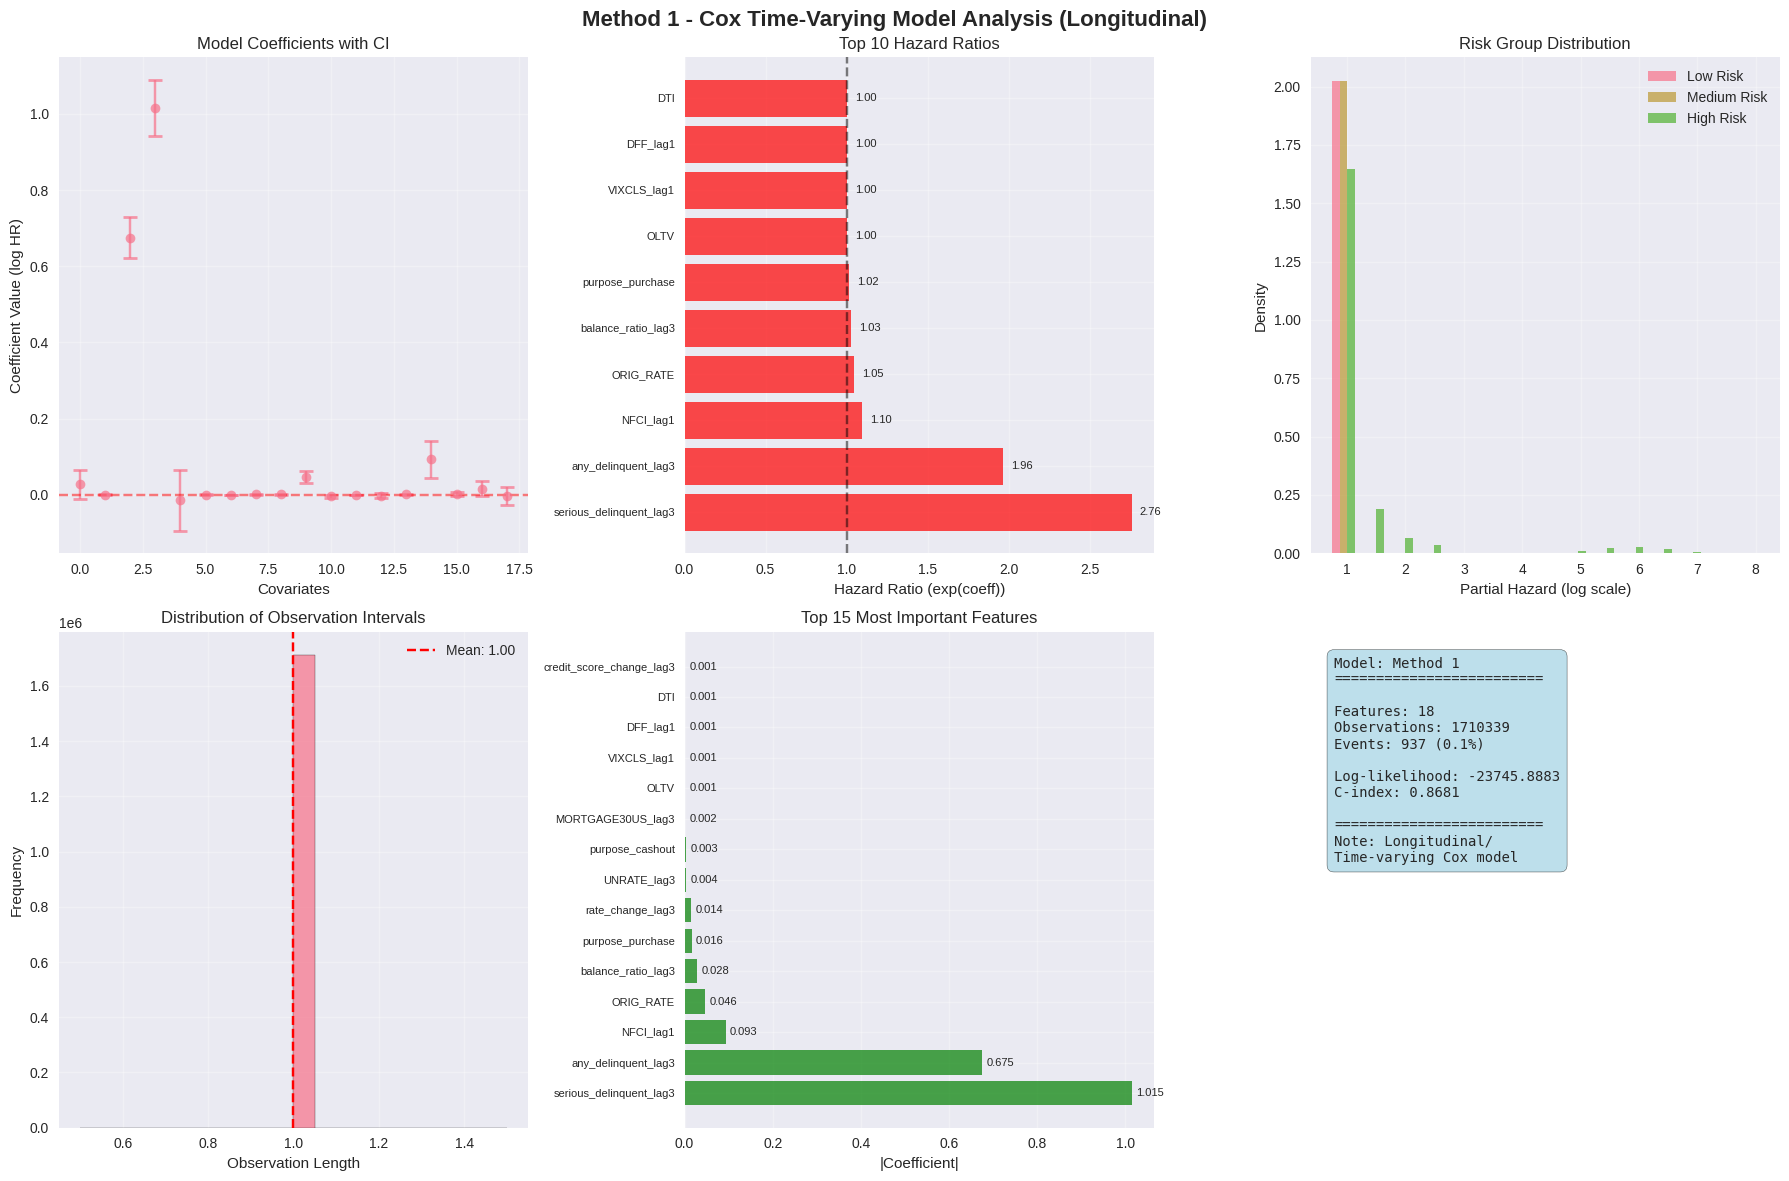

Processing Method 2...


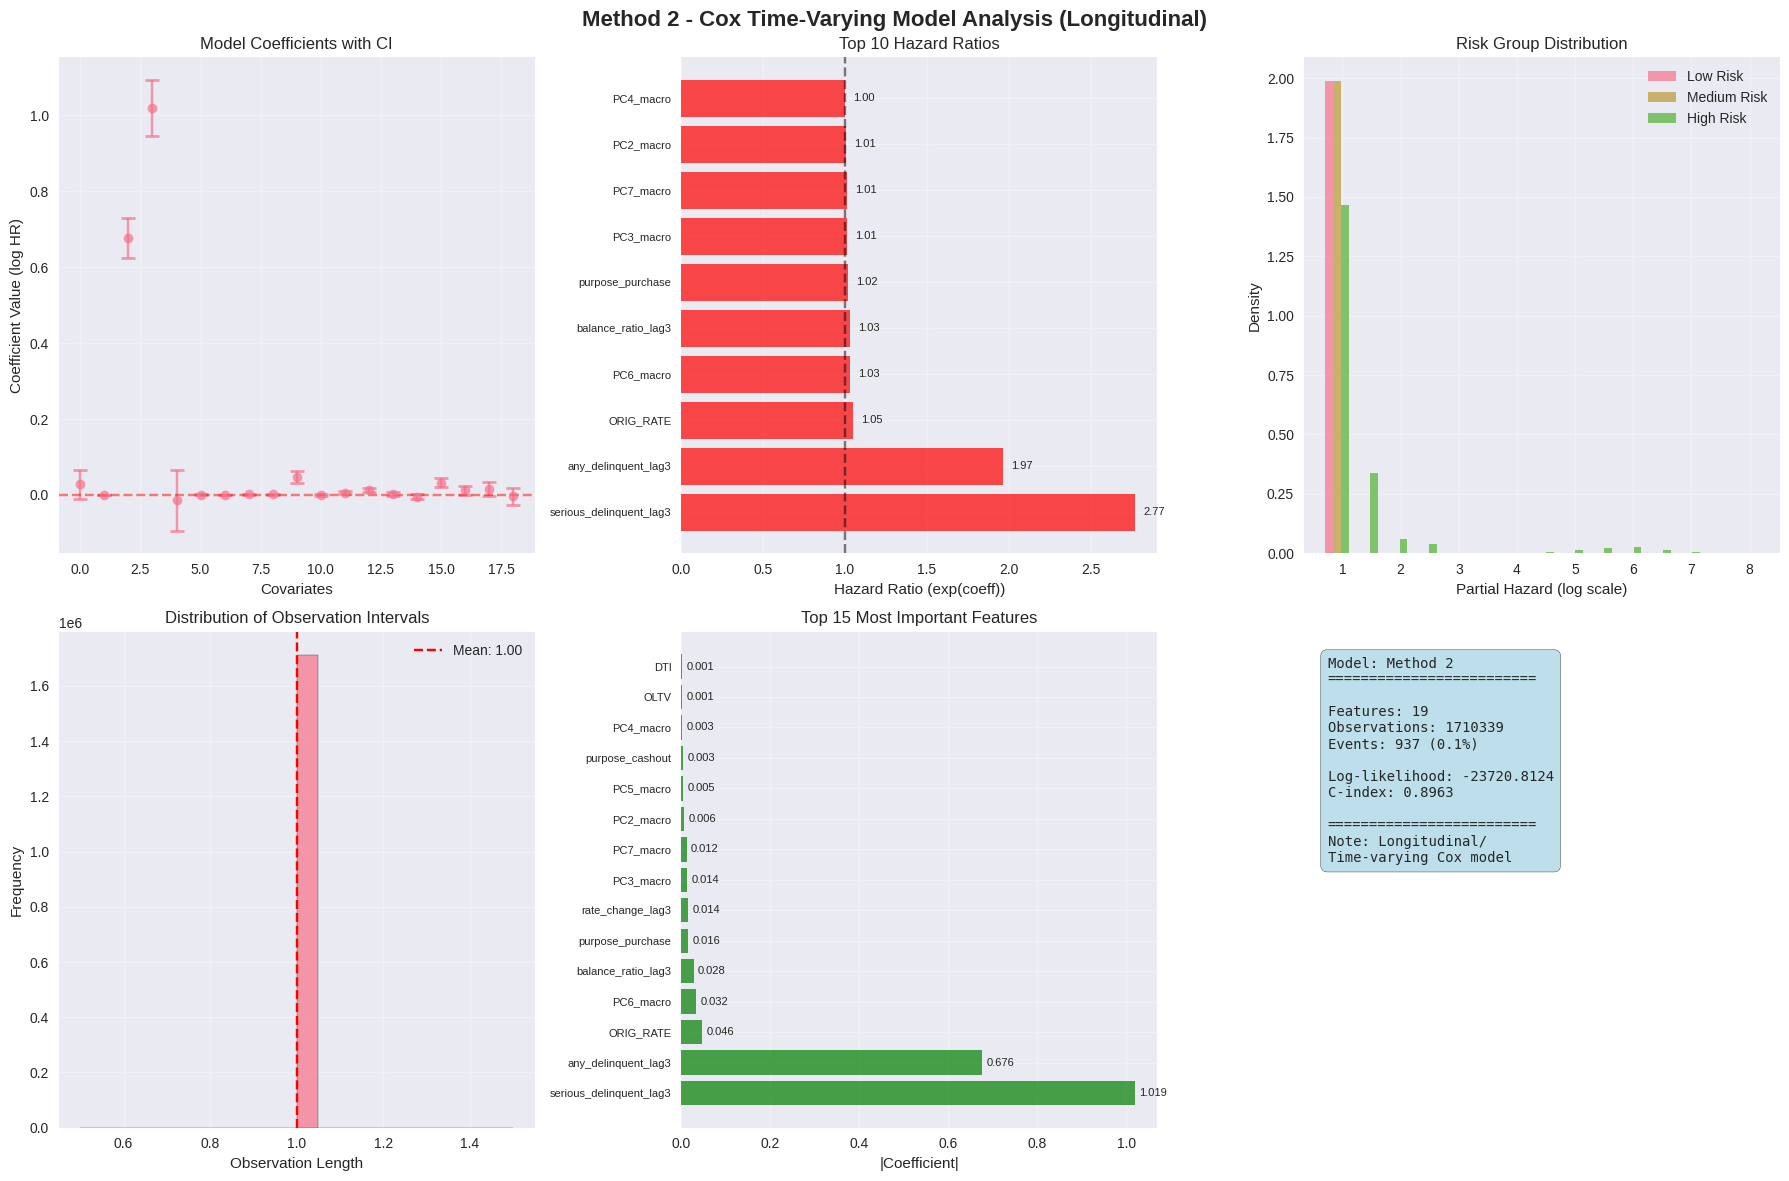

Processing Method 3...


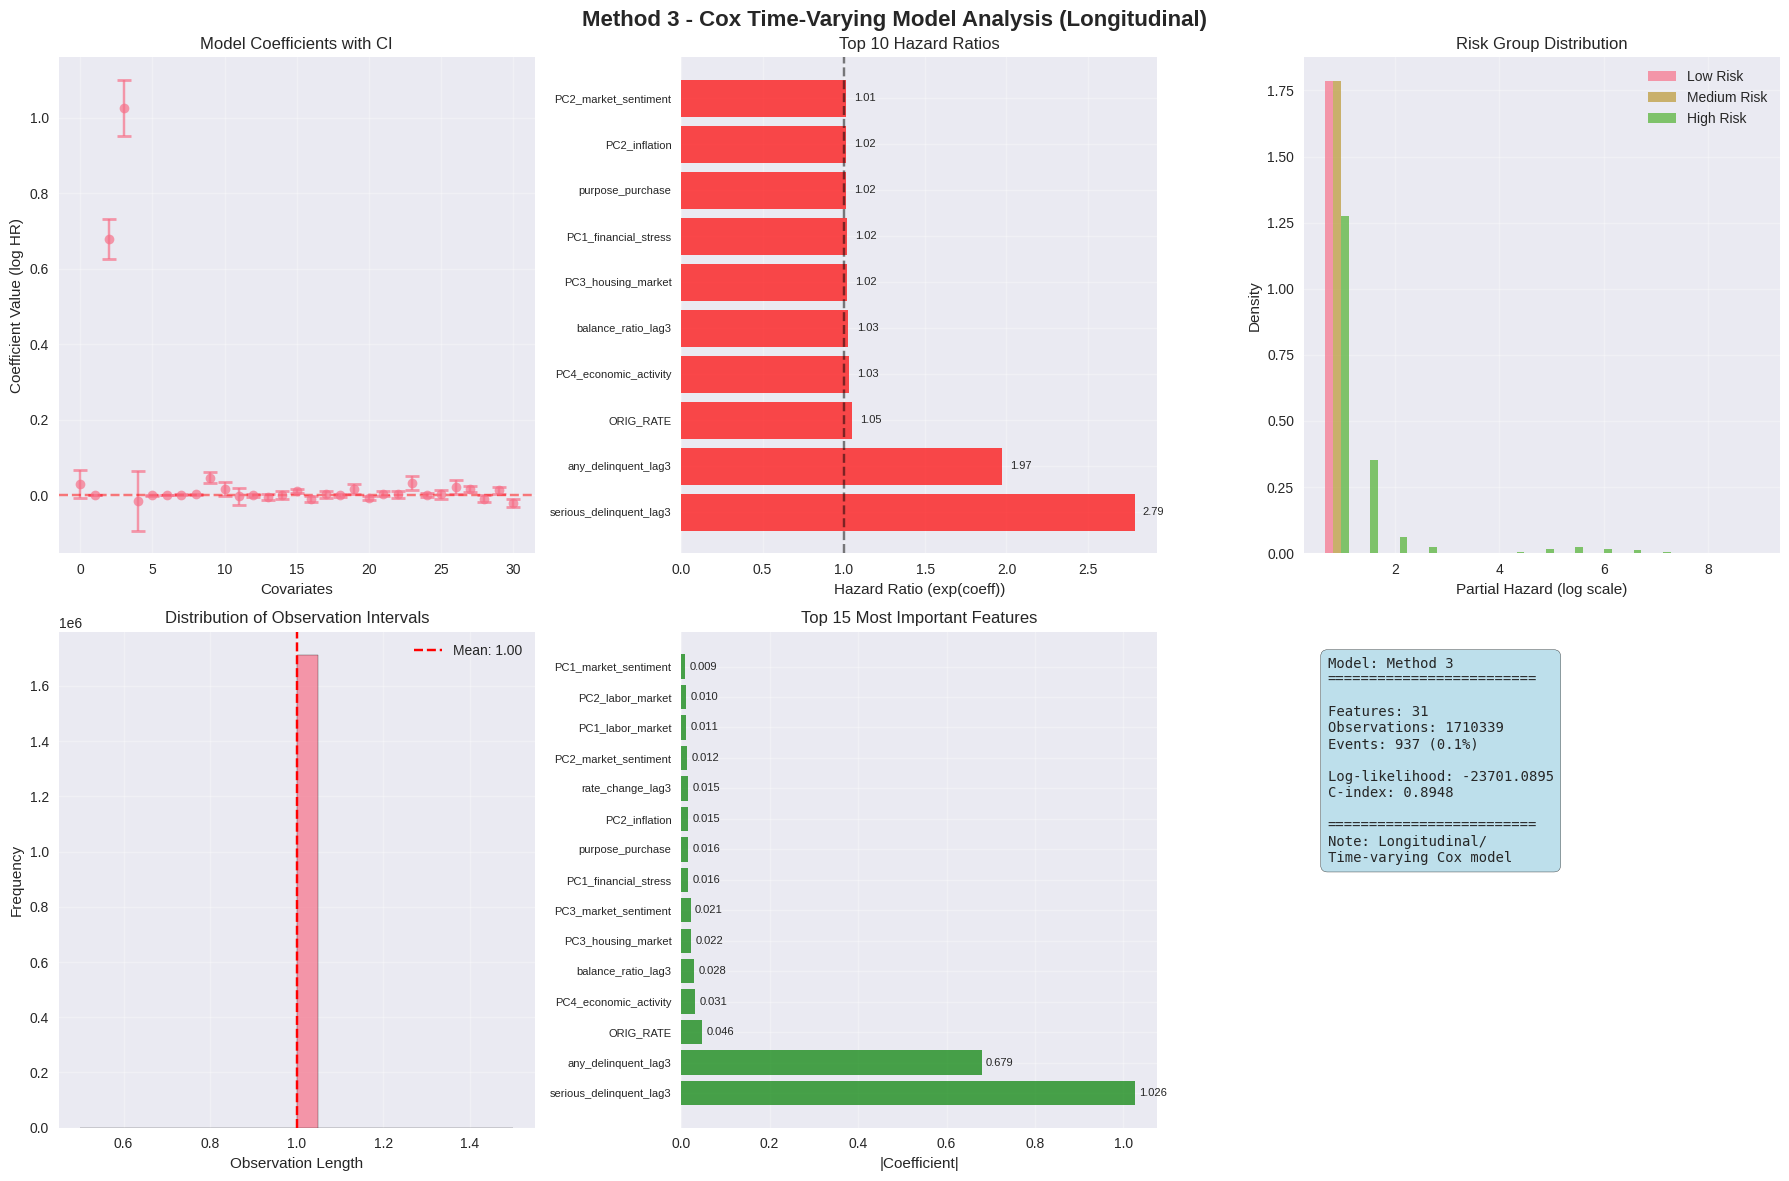

Processing Method 4...


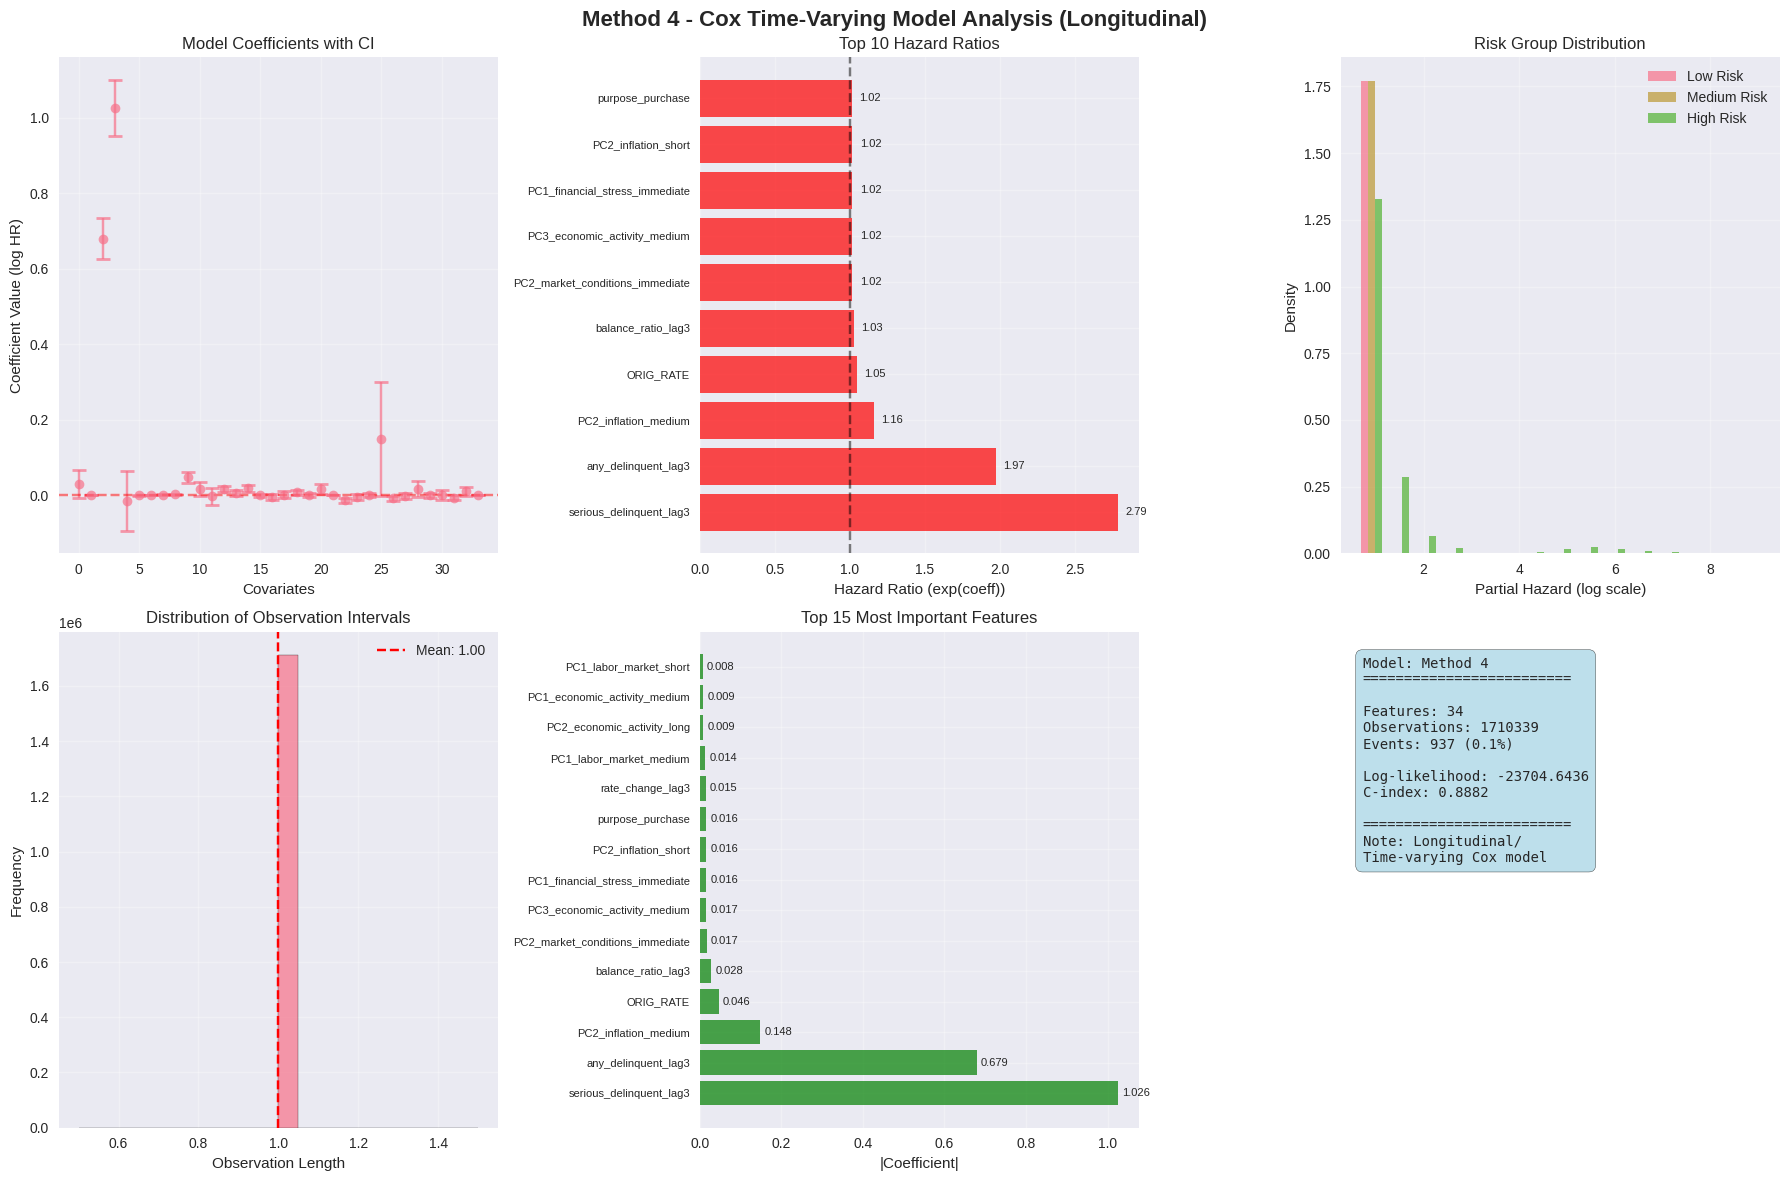


Note: These plots are specifically designed for Cox Time-Varying models used with longitudinal data.
Key differences from regular Cox models:
- No Schoenfeld residuals (not applicable for time-varying models)
- Focus on longitudinal data patterns
- Risk assessment considers latest observation per individual
- Analysis of observation intervals and patterns


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines.utils import concordance_index
from lifelines import CoxTimeVaryingFitter
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

def plot_individual_coxTV_analysis(model, results, test_data, method_name):
    """Generate comprehensive plots for Cox Time-Varying model (longitudinal data)"""

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle(f'{method_name} - Cox Time-Varying Model Analysis (Longitudinal)', fontsize=16, fontweight='bold')

    # 1. Coefficient Plot with Confidence Intervals
    ax1 = axes[0, 0]
    if hasattr(model, 'params_') and model.params_ is not None:
        coeffs = model.params_
        if hasattr(model, 'confidence_intervals_') and model.confidence_intervals_ is not None:
            ci = model.confidence_intervals_
            # Handle confidence intervals properly
            lower_ci = ci.iloc[:, 0]  # Lower bound
            upper_ci = ci.iloc[:, 1]  # Upper bound

            ax1.errorbar(range(len(coeffs)), coeffs.values,
                        yerr=[coeffs.values - lower_ci.values, upper_ci.values - coeffs.values],
                        fmt='o', capsize=5, capthick=2, alpha=0.7)
        else:
            ax1.scatter(range(len(coeffs)), coeffs.values, alpha=0.7)

        # Add coefficient names if not too many
        if len(coeffs) <= 15:
            ax1.set_xticks(range(len(coeffs)))
            ax1.set_xticklabels(coeffs.index, rotation=45, ha='right', fontsize=8)

        ax1.set_xlabel('Covariates')
        ax1.set_ylabel('Coefficient Value (log HR)')
        ax1.set_title('Model Coefficients with CI')
        ax1.grid(True, alpha=0.3)
        ax1.axhline(y=0, color='red', linestyle='--', alpha=0.5)
    else:
        ax1.text(0.5, 0.5, 'Coefficients not available',
                ha='center', va='center', transform=ax1.transAxes)

    # 2. Hazard Ratios Plot
    ax2 = axes[0, 1]
    if hasattr(model, 'params_') and model.params_ is not None:
        hazard_ratios = np.exp(model.params_)
        top_features = hazard_ratios.abs().nlargest(min(10, len(hazard_ratios)))

        colors = ['red' if x > 1 else 'blue' for x in top_features.values]
        bars = ax2.barh(range(len(top_features)), top_features.values, color=colors, alpha=0.7)
        ax2.set_yticks(range(len(top_features)))
        ax2.set_yticklabels(top_features.index, fontsize=8)
        ax2.set_xlabel('Hazard Ratio (exp(coeff))')
        ax2.set_title(f'Top {len(top_features)} Hazard Ratios')
        ax2.axvline(x=1, color='black', linestyle='--', alpha=0.5)
        ax2.grid(True, alpha=0.3)

        # Add values on bars
        for i, v in enumerate(top_features.values):
            ax2.text(v + 0.05 if v > 1 else v - 0.05, i, f'{v:.2f}',
                    va='center', ha='left' if v > 1 else 'right', fontsize=8)
    else:
        ax2.text(0.5, 0.5, 'Hazard ratios not available',
                ha='center', va='center', transform=ax2.transAxes)

    # 3. Partial Hazard Distribution by Risk Groups
    ax3 = axes[0, 2]
    try:
        # For longitudinal data, we need to be careful about prediction
        if hasattr(model, 'predict_partial_hazard'):
            # Get unique individuals for risk grouping
            if 'id' in test_data.columns:
                # Get latest observation for each individual
                latest_obs = test_data.groupby('id').last().reset_index()
                partial_hazards = model.predict_partial_hazard(latest_obs)
            else:
                partial_hazards = model.predict_partial_hazard(test_data)

            # Create risk groups
            q33, q67 = np.percentile(partial_hazards, [33, 67])
            low_risk = partial_hazards <= q33
            medium_risk = (partial_hazards > q33) & (partial_hazards < q67)
            high_risk = partial_hazards >= q67

            ax3.hist([partial_hazards[low_risk], partial_hazards[medium_risk], partial_hazards[high_risk]],
                    label=['Low Risk', 'Medium Risk', 'High Risk'],
                    alpha=0.7, bins=15, density=True)

            ax3.set_xlabel('Partial Hazard (log scale)')
            ax3.set_ylabel('Density')
            ax3.set_title('Risk Group Distribution')
            ax3.legend()
            ax3.grid(True, alpha=0.3)
        else:
            ax3.text(0.5, 0.5, 'Partial hazard\nprediction not available',
                    ha='center', va='center', transform=ax3.transAxes)
    except Exception as e:
        ax3.text(0.5, 0.5, f'Risk analysis error:\n{str(e)[:50]}...',
                ha='center', va='center', transform=ax3.transAxes)

    # 4. Longitudinal Data Pattern Analysis
    ax4 = axes[1, 0]
    try:
        # Analyze observation patterns in longitudinal data
        if 'start' in test_data.columns and 'stop' in test_data.columns:
            observation_lengths = test_data['stop'] - test_data['start']

            ax4.hist(observation_lengths, bins=20, alpha=0.7, edgecolor='black')
            ax4.set_xlabel('Observation Length')
            ax4.set_ylabel('Frequency')
            ax4.set_title('Distribution of Observation Intervals')
            ax4.grid(True, alpha=0.3)

            # Add statistics
            mean_length = observation_lengths.mean()
            ax4.axvline(mean_length, color='red', linestyle='--',
                       label=f'Mean: {mean_length:.2f}')
            ax4.legend()

        elif 'id' in test_data.columns:
            # Count observations per individual
            obs_per_id = test_data['id'].value_counts()

            ax4.hist(obs_per_id, bins=min(20, obs_per_id.nunique()), alpha=0.7, edgecolor='black')
            ax4.set_xlabel('Number of Observations per Individual')
            ax4.set_ylabel('Frequency')
            ax4.set_title('Longitudinal Observation Pattern')
            ax4.grid(True, alpha=0.3)

            # Add statistics
            mean_obs = obs_per_id.mean()
            ax4.axvline(mean_obs, color='red', linestyle='--',
                       label=f'Mean: {mean_obs:.1f}')
            ax4.legend()
        else:
            ax4.text(0.5, 0.5, 'Longitudinal structure\nanalysis not available\n(missing id/start/stop)',
                    ha='center', va='center', transform=ax4.transAxes)
    except Exception as e:
        ax4.text(0.5, 0.5, f'Pattern analysis error:\n{str(e)[:50]}...',
                ha='center', va='center', transform=ax4.transAxes)

    # 5. Feature Importance (based on coefficient magnitude)
    ax5 = axes[1, 1]
    if hasattr(model, 'params_') and model.params_ is not None:
        feature_importance = model.params_.abs().nlargest(min(15, len(model.params_)))

        bars = ax5.barh(range(len(feature_importance)), feature_importance.values, alpha=0.7, color='green')
        ax5.set_yticks(range(len(feature_importance)))
        ax5.set_yticklabels(feature_importance.index, fontsize=8)
        ax5.set_xlabel('|Coefficient|')
        ax5.set_title(f'Top {len(feature_importance)} Most Important Features')
        ax5.grid(True, alpha=0.3)

        # Add values on bars
        for i, v in enumerate(feature_importance.values):
            ax5.text(v + max(feature_importance.values)*0.01, i, f'{v:.3f}',
                    va='center', ha='left', fontsize=8)
    else:
        ax5.text(0.5, 0.5, 'Feature importance\nnot available',
                ha='center', va='center', transform=ax5.transAxes)

    # 6. Model Statistics Summary
    ax6 = axes[1, 2]
    ax6.axis('off')

    # Collect model statistics
    stats_text = f"Model: {method_name}\n"
    stats_text += "=" * 25 + "\n\n"

    if hasattr(model, 'params_') and model.params_ is not None:
        stats_text += f"Features: {len(model.params_)}\n"

    # Data characteristics
    if isinstance(test_data, pd.DataFrame):
        stats_text += f"Observations: {len(test_data)}\n"

        if 'id' in test_data.columns:
            unique_ids = test_data['id'].nunique()
            stats_text += f"Individuals: {unique_ids}\n"
            avg_obs = len(test_data) / unique_ids
            stats_text += f"Avg obs/person: {avg_obs:.1f}\n"

        # Event information
        if 'event' in test_data.columns:
            events = test_data['event'].sum()
            event_rate = events / len(test_data)
            stats_text += f"Events: {events} ({event_rate:.1%})\n"

    # Model fit statistics
    if hasattr(model, 'log_likelihood_'):
        stats_text += f"\nLog-likelihood: {model.log_likelihood_:.4f}\n"

    if hasattr(model, 'AIC_'):
        stats_text += f"AIC: {model.AIC_:.4f}\n"

    # Try to calculate concordance index
    try:
        if hasattr(model, 'predict_partial_hazard'):
            # For longitudinal data, use appropriate columns
            duration_col = None
            event_col = None

            # Common column names for longitudinal survival data
            for dur_name in ['stop', 'T', 'duration', 'time']:
                if dur_name in test_data.columns:
                    duration_col = dur_name
                    break

            for event_name in ['event', 'E', 'status']:
                if event_name in test_data.columns:
                    event_col = event_name
                    break

            if duration_col and event_col:
                partial_hazards = model.predict_partial_hazard(test_data)
                c_index = concordance_index(test_data[duration_col],
                                          -partial_hazards,
                                          test_data[event_col])
                stats_text += f"C-index: {c_index:.4f}\n"
    except Exception as e:
        stats_text += f"C-index: Error computing\n"

    # Add note about longitudinal nature
    stats_text += f"\n{'='*25}\n"
    stats_text += "Note: Longitudinal/\nTime-varying Cox model"

    ax6.text(0.05, 0.95, stats_text, transform=ax6.transAxes, fontsize=10,
            verticalalignment='top', family='monospace',
            bbox=dict(boxstyle="round,pad=0.5", facecolor="lightblue", alpha=0.8))

    plt.tight_layout()
    return fig


for i, (method_name, model) in enumerate(models_dict.items()):
    print(f"Processing {method_name}...")
    try:
        fig = plot_individual_coxTV_analysis(model, results_list[i],
                                           test_datasets_dict[method_name], method_name)
        plt.show()
    except Exception as e:
        print(f"Error processing {method_name}: {str(e)}")
        continue



=== Processing Model: Baseline Loan + Macro Lags ===


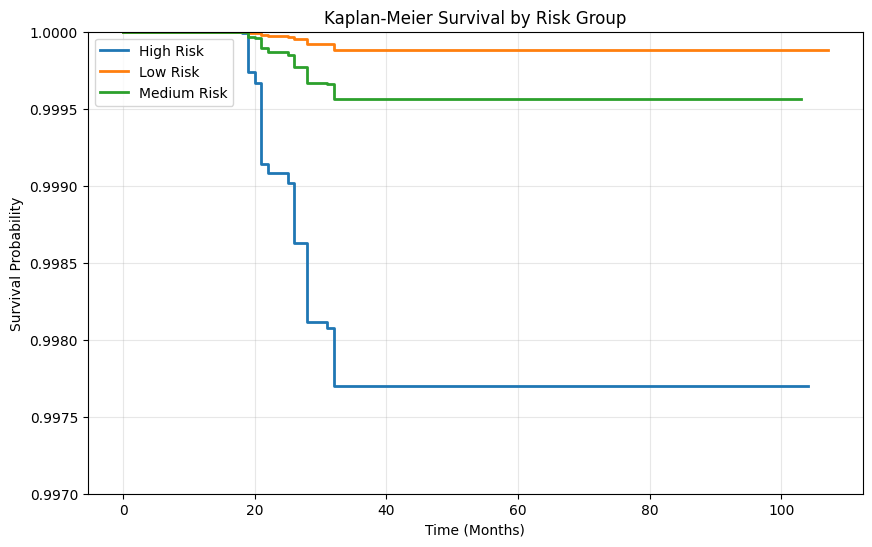


📊 Risk Group Summary - Baseline Loan + Macro Lags
    risk_group  n_loans  n_defaults  default_rate
0    High Risk    51305         102          0.20
1     Low Risk    51305           4          0.01
2  Medium Risk    52860          12          0.02

=== Processing Model: Loan + Traditional PCA Macros ===


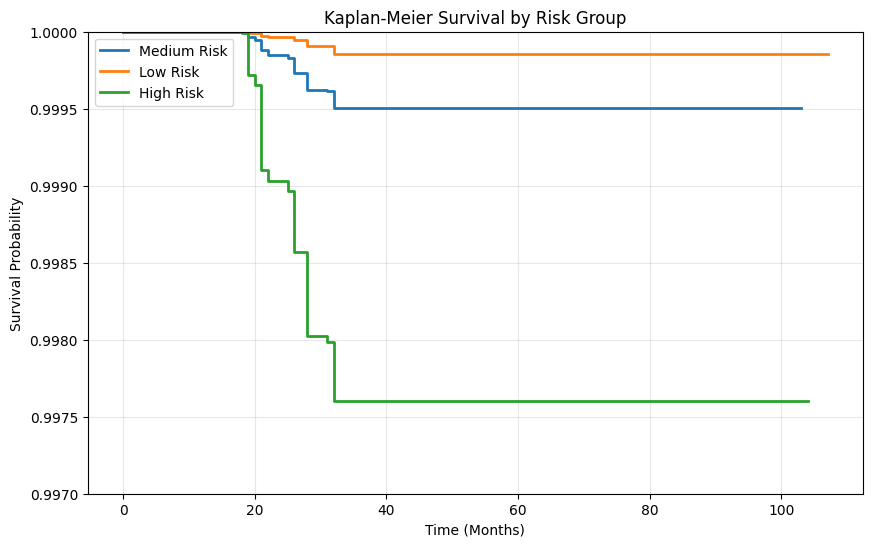


📊 Risk Group Summary - Loan + Traditional PCA Macros
    risk_group  n_loans  n_defaults  default_rate
0    High Risk    51305         106          0.21
1     Low Risk    51305           0          0.00
2  Medium Risk    52860          12          0.02

=== Processing Model: Loan + Domain PCA Macros ===


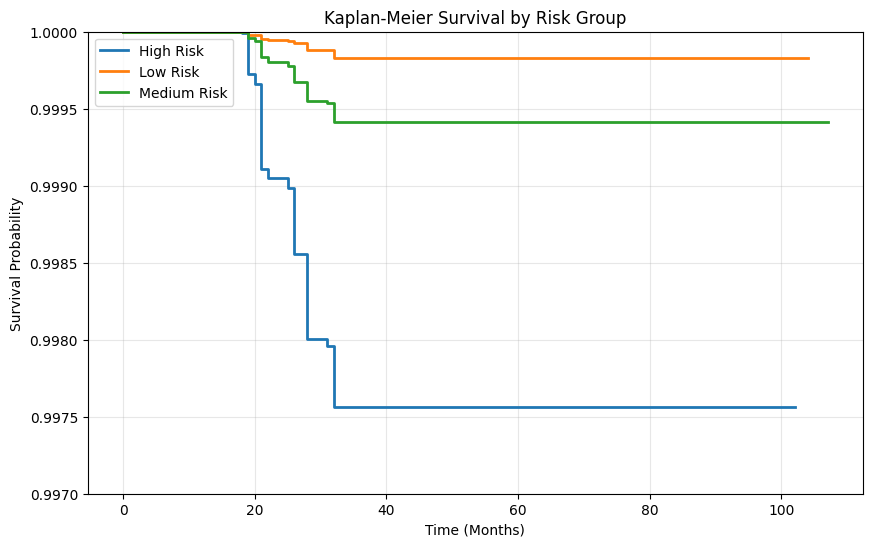


📊 Risk Group Summary - Loan + Domain PCA Macros
    risk_group  n_loans  n_defaults  default_rate
0    High Risk    51305         103          0.20
1     Low Risk    51305           2          0.00
2  Medium Risk    52860          13          0.02

=== Processing Model: Lag-Aware Domain PCA + Loan ===


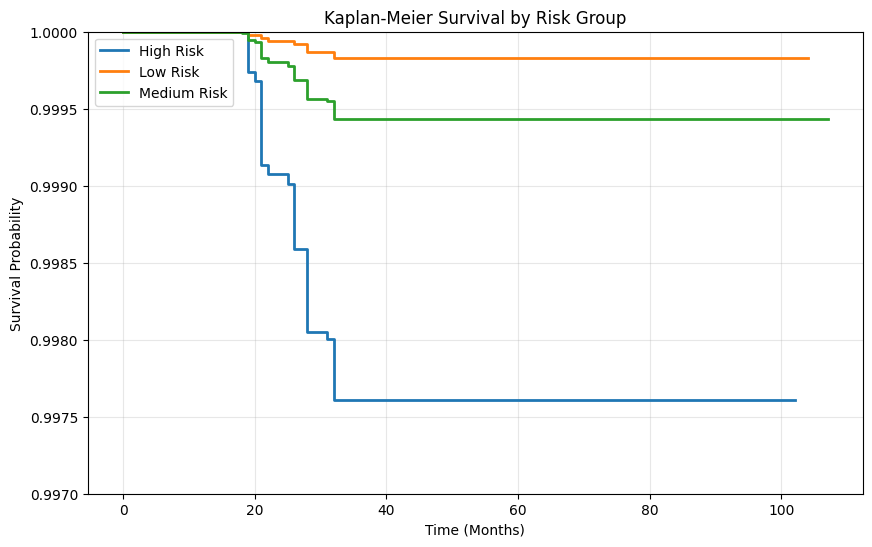


📊 Risk Group Summary - Lag-Aware Domain PCA + Loan
    risk_group  n_loans  n_defaults  default_rate
0    High Risk    51305         104          0.20
1     Low Risk    51305           2          0.00
2  Medium Risk    52860          12          0.02


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

def assign_risk_groups(cph, df, id_col='LOAN_ID', start_col='start', stop_col='stop'):
    """
    Assign risk groups based on predicted partial hazards using 33rd and 67th percentiles.
    """
    df_copy = df.copy()

    # Latest observation per loan
    latest_obs = df_copy.groupby(id_col).last().reset_index()

    # Predict partial hazards
    partial_hazards = cph.predict_partial_hazard(latest_obs)

    # Percentiles
    q33, q67 = np.percentile(partial_hazards, [33, 67])

    # Assign labels
    def risk_label(h):
        if h <= q33:
            return 'Low Risk'
        elif h < q67:
            return 'Medium Risk'
        else:
            return 'High Risk'

    latest_obs['risk_group'] = partial_hazards.apply(risk_label)

    # Merge back to full df
    df_copy = df_copy.merge(latest_obs[[id_col, 'risk_group']], on=id_col, how='left')
    return df_copy


def km_survival_by_risk_group(df, id_col="LOAN_ID", time_col="stop", event_col="event", risk_col="risk_group", zoom=None):
    kmf = KaplanMeierFitter()
    plt.figure(figsize=(10, 6))

    survival_curves = {}
    for group in df[risk_col].unique():
        group_df = df[df[risk_col] == group]
        kmf.fit(durations=group_df[time_col], event_observed=group_df[event_col], label=group)
        kmf.plot_survival_function(ci_show=False, lw=2)
        survival_curves[group] = kmf.survival_function_

    plt.title("Kaplan-Meier Survival by Risk Group")
    plt.xlabel("Time (Months)")
    plt.ylabel("Survival Probability")
    if zoom:
        plt.ylim(*zoom)
    plt.grid(True, alpha=0.3)
    plt.show()

    return survival_curves


def summarize_risk_groups(df, id_col="LOAN_ID", event_col="event"):
    latest_obs = df.groupby(id_col).last().reset_index()
    summary = (
        latest_obs.groupby("risk_group")
        .agg(
            n_loans=(id_col, "count"),
            n_defaults=(event_col, "sum"),
            default_rate=(event_col, "mean")
        )
        .reset_index()
    )
    summary["default_rate"] = (summary["default_rate"] * 100).round(2)
    return summary


datasets = {
    "Baseline Loan + Macro Lags": df,
    "Loan + Traditional PCA Macros": df2,
    "Loan + Domain PCA Macros": df3,
    "Lag-Aware Domain PCA + Loan": df4
}

models = {
    "Baseline Loan + Macro Lags": model1,
    "Loan + Traditional PCA Macros": model_pca,
    "Loan + Domain PCA Macros": model_domain_pca,
    "Lag-Aware Domain PCA + Loan": model_lag_pca
}

# Store results
all_km_curves = {}
all_risk_summaries = {}

for name in models.keys():
    print(f"\n=== Processing Model: {name} ===")

    df_model = datasets[name]
    model = models[name]

    # Assign risk groups
    df_with_risk = assign_risk_groups(model, df_model, id_col="LOAN_ID")

    # Kaplan-Meier curves
    km_curves = km_survival_by_risk_group(df_with_risk, zoom=(0.997, 1.0))

    # Risk group summary
    risk_summary = summarize_risk_groups(df_with_risk)
    print(f"\n📊 Risk Group Summary - {name}")
    print(risk_summary)

    # Store results
    all_km_curves[name] = km_curves
    all_risk_summaries[name] = risk_summary


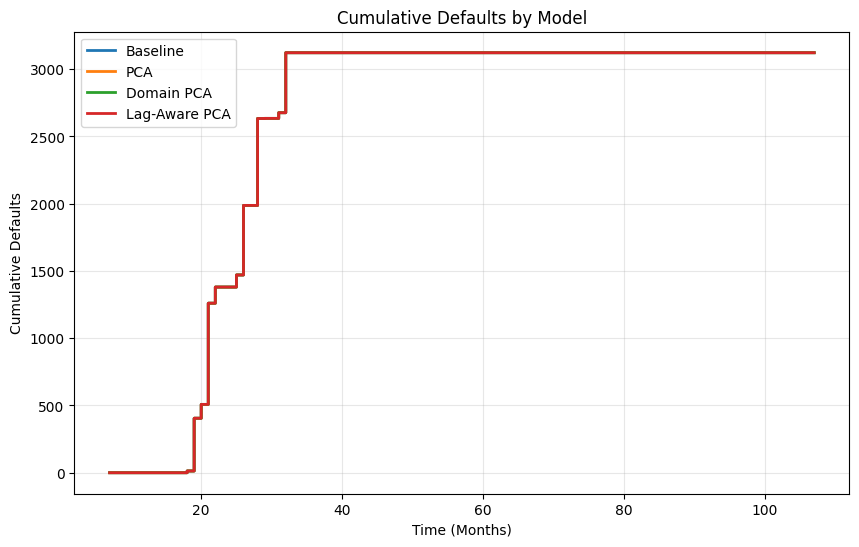

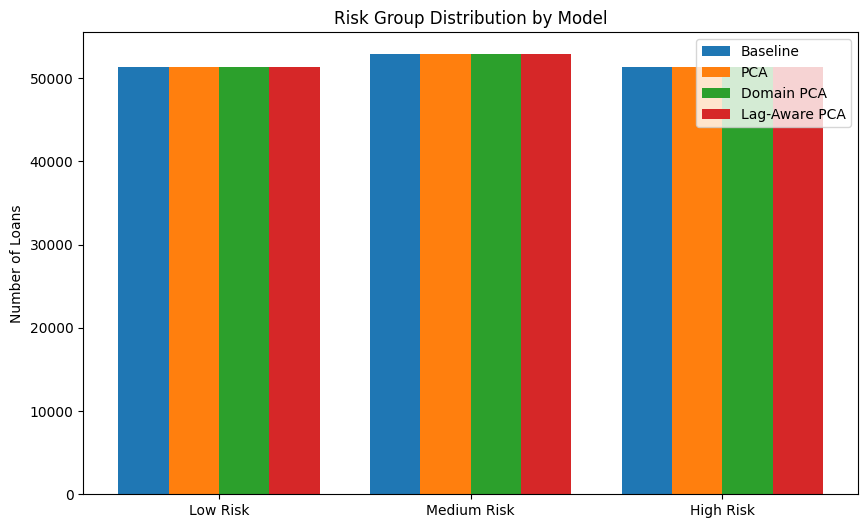

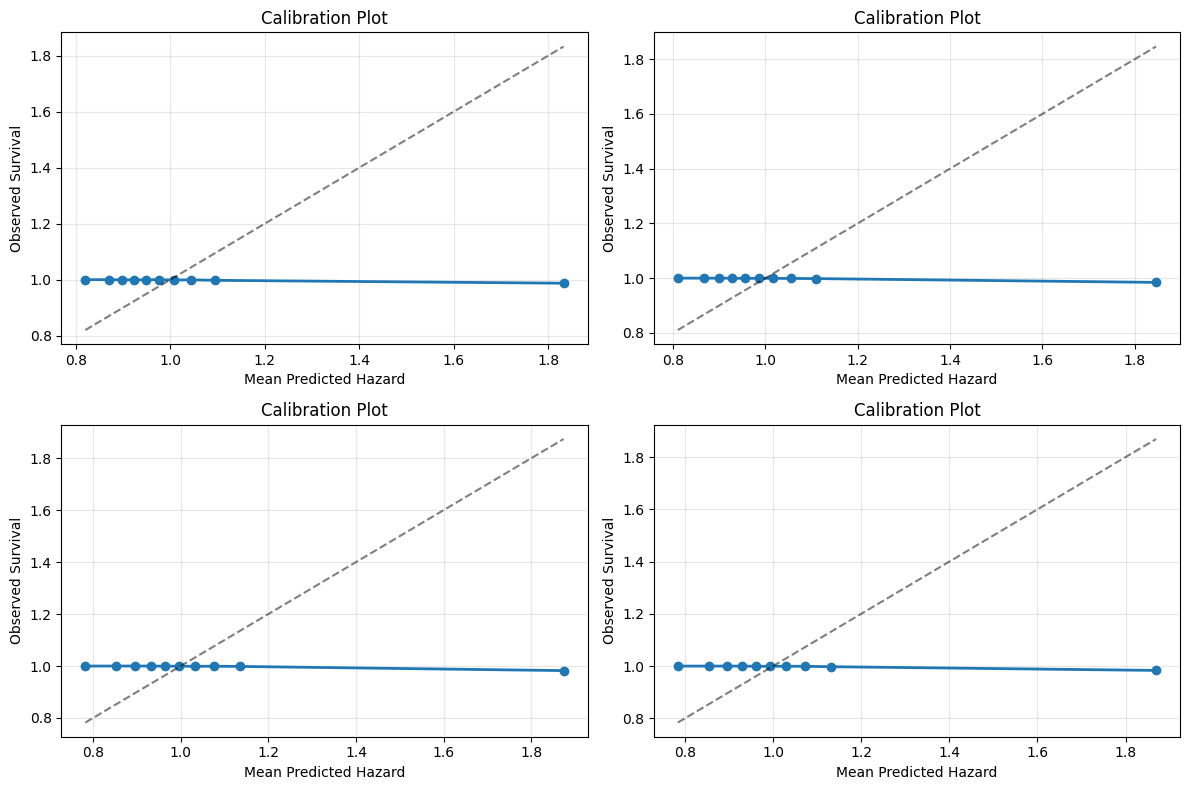

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter


# 1️⃣ Baseline: Loan features + macro lags
train_pd = train_start_stop.to_pandas()
test_pd = test_start_stop.to_pandas()
df = pd.concat([train_pd, test_pd], ignore_index=True)

# 2️⃣ Loan features + Traditional PCA on macro vars
train_pd = train_pca
test_pd = test_pca
df2 = pd.concat([train_pd, test_pd], ignore_index=True)

# 3️⃣ Loan features + Domain-specific PCA on macro vars
train_pd = train_domain_pca
test_pd = test_domain_pca
df3 = pd.concat([train_pd, test_pd], ignore_index=True)

# 4️⃣ Lag-aware Domain PCA + Loan features
train_pd = train_lag_pca
test_pd = test_lag_pca
df4 = pd.concat([train_pd, test_pd], ignore_index=True)

def assign_risk_groups(cph, df, id_col='LOAN_ID', start_col='start', stop_col='stop'):
    df_copy = df.copy()
    latest_obs = df_copy.groupby(id_col).last().reset_index()
    partial_hazards = cph.predict_partial_hazard(latest_obs)
    q33, q67 = np.percentile(partial_hazards, [33, 67])

    def risk_label(h):
        if h <= q33:
            return 'Low Risk'
        elif h < q67:
            return 'Medium Risk'
        else:
            return 'High Risk'

    latest_obs['risk_group'] = partial_hazards.apply(risk_label)
    df_copy = df_copy.merge(latest_obs[[id_col, 'risk_group']], on=id_col, how='left')
    return df_copy

def cumulative_defaults(df, time_col='stop', event_col='event', label='Model'):
    df_sorted = df.sort_values(time_col)
    df_sorted['cum_defaults'] = df_sorted[event_col].cumsum()
    plt.plot(df_sorted[time_col], df_sorted['cum_defaults'], lw=2, label=label)

def plot_risk_group_distribution(df_dict):
    plt.figure(figsize=(10,6))
    width = 0.2
    labels = ['Low Risk', 'Medium Risk', 'High Risk']
    x = np.arange(len(labels))

    for i, (name, df) in enumerate(df_dict.items()):
        latest_obs = df.groupby('LOAN_ID').last().reset_index()
        counts = latest_obs['risk_group'].value_counts()
        counts = [counts.get(label, 0) for label in labels]
        plt.bar(x + i*width, counts, width=width, label=name)

    plt.xticks(x + width*1.5, labels)
    plt.ylabel("Number of Loans")
    plt.title("Risk Group Distribution by Model")
    plt.legend()
    plt.show()

def calibration_plot(df, cph, id_col='LOAN_ID', stop_col='stop', event_col='event', n_bins=10):
    latest_obs = df.groupby(id_col).last().reset_index()
    predicted_hazard = cph.predict_partial_hazard(latest_obs)

    latest_obs['pred_bin'] = pd.qcut(predicted_hazard, n_bins, labels=False)
    observed_survival = []
    predicted_mean = []

    kmf = KaplanMeierFitter()

    for b in range(n_bins):
        bin_df = latest_obs[latest_obs['pred_bin'] == b]
        kmf.fit(durations=bin_df[stop_col], event_observed=bin_df[event_col])
        observed_survival.append(kmf.survival_function_at_times(bin_df[stop_col].max()).values[0])
        predicted_mean.append(predicted_hazard[bin_df.index].mean())

    plt.plot(predicted_mean, observed_survival, 'o-', lw=2)
    plt.plot([min(predicted_mean), max(predicted_mean)], [min(predicted_mean), max(predicted_mean)], 'k--', alpha=0.5)
    plt.xlabel("Mean Predicted Hazard")
    plt.ylabel("Observed Survival")
    plt.title("Calibration Plot")
    plt.grid(True, alpha=0.3)

datasets = {
    "Baseline": df,
    "PCA": df2,
    "Domain PCA": df3,
    "Lag-Aware PCA": df4
}

models_dict = {
    "Baseline": model1,
    "PCA": model_pca,
    "Domain PCA": model_domain_pca,
    "Lag-Aware PCA": model_lag_pca
}

# 1. Risk group assignment
dfs_with_risk = {}
for name, data in datasets.items():
    dfs_with_risk[name] = assign_risk_groups(models_dict[name], data)

# 2. Cumulative Defaults
plt.figure(figsize=(10,6))
for name, df_risk in dfs_with_risk.items():
    cumulative_defaults(df_risk, label=name)
plt.xlabel("Time (Months)")
plt.ylabel("Cumulative Defaults")
plt.title("Cumulative Defaults by Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3. Risk Group Distribution
plot_risk_group_distribution(dfs_with_risk)

# 4. Calibration Plots
plt.figure(figsize=(12,8))
for i, (name, df_risk) in enumerate(dfs_with_risk.items(),1):
    plt.subplot(2,2,i)
    calibration_plot(df_risk, models_dict[name])
plt.tight_layout()
plt.show()


In [ ]:
from lifelines.utils import concordance_index
from lifelines import KaplanMeierFitter
import numpy as np
import pandas as pd



df_test = test_start_stop.to_pandas()  # if Polars
df2_test = test_pca                   # assumed already pandas
df3_test = test_domain_pca
df4_test = test_lag_pca

datasets_test = {
    "Baseline": df_test,
    "PCA": df2_test,
    "Domain PCA": df3_test,
    "Lag-Aware PCA": df4_test
}


# Models
models_dict = {
    "Baseline": model1,
    "PCA": model_pca,
    "Domain PCA": model_domain_pca,
    "Lag-Aware PCA": model_lag_pca
}

# Compute Metrics
metrics = []

for name, model in models_dict.items():
    dataset = datasets_test[name]

    # Latest observation per loan
    latest = dataset.groupby('LOAN_ID').last().reset_index()

    # Partial hazard
    ph = model.predict_partial_hazard(latest).values.flatten()

    # C-index (higher is better)
    c_index = concordance_index(latest['stop'], -ph, latest['event'])

    # Brier score at max follow-up using KM as baseline
    T_max = latest['stop'].max()
    kmf = KaplanMeierFitter()
    kmf.fit(durations=latest['stop'], event_observed=latest['event'])
    S_t = kmf.survival_function_at_times(T_max).values[0]  # KM survival at T_max
    surv_probs = np.exp(-ph * -np.log(S_t))                 # approximate predicted survival
    brier = np.mean((surv_probs - (latest['event'] == 0))**2)

    # Partial log-likelihood from Cox TV model
    log_lik = model.log_likelihood_

    metrics.append({
        "Model": name,
        "C-index": c_index,
        "Brier": brier,
        "Log-Likelihood": log_lik
    })

metrics_df = pd.DataFrame(metrics)
print(metrics_df)


           Model   C-index     Brier  Log-Likelihood
0       Baseline  0.892454  0.000807   -23745.888316
1            PCA  0.914159  0.000807   -23720.812445
2     Domain PCA  0.919144  0.000807   -23701.089461
3  Lag-Aware PCA  0.912911  0.000807   -23704.643570


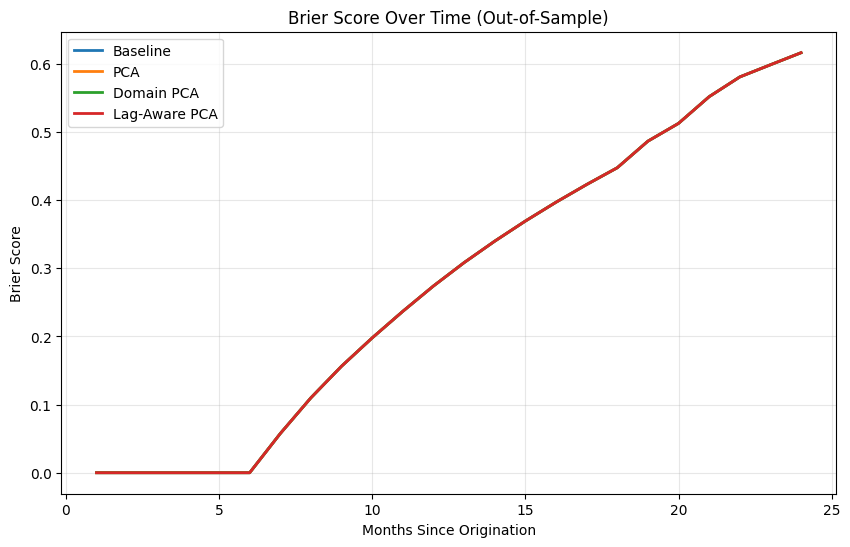

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Test datasets
datasets_test = {
    "Baseline": df_test,
    "PCA": df2_test,
    "Domain PCA": df3_test,
    "Lag-Aware PCA": df4_test
}

# Models
models_dict = {
    "Baseline": model1,
    "PCA": model_pca,
    "Domain PCA": model_domain_pca,
    "Lag-Aware PCA": model_lag_pca
}

time_points = np.arange(1, 25)  # 1 to 24 months
brier_scores = {}

for name, model in models_dict.items():
    dataset = datasets_test[name]
    latest = dataset.groupby('LOAN_ID').last().reset_index()

    # Partial hazard
    ph = model.predict_partial_hazard(latest).values.flatten()

    # Fit Kaplan-Meier for censoring
    kmf = KaplanMeierFitter()
    kmf.fit(durations=latest['stop'], event_observed=latest['event'])

    # Survival probabilities from KM at each time point
    km_surv = kmf.survival_function_

    brier = []
    for t in time_points:
        # Get KM probability at time t (nearest)
        km_prob = km_surv.iloc[km_surv.index.get_indexer([t], method='nearest')[0], 0]

        # Predicted survival for each loan
        S_t = np.exp(-ph * -np.log(km_prob))  # Avoid cumulative_hazard

        # Event indicator: 1 if survived beyond t, 0 if event before t
        event_t = (latest['stop'] > t).astype(int)

        # Brier score = mean squared error
        brier.append(np.mean((S_t - event_t)**2))

    brier_scores[name] = brier

# Plot Brier score curves
plt.figure(figsize=(10,6))
for name, scores in brier_scores.items():
    plt.plot(time_points, scores, lw=2, label=name)

plt.xlabel("Months Since Origination")
plt.ylabel("Brier Score")
plt.title("Brier Score Over Time (Out-of-Sample)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


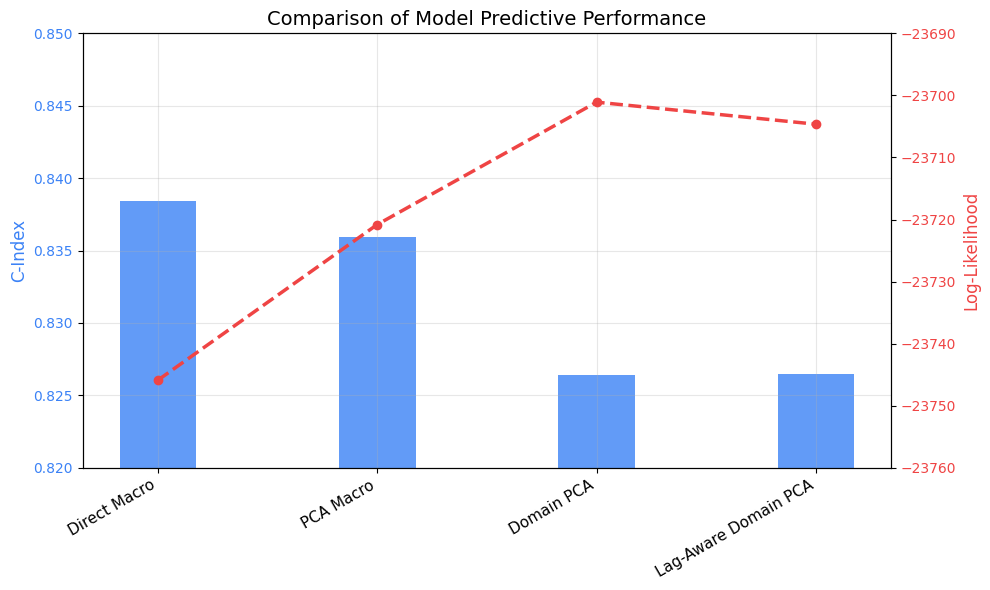

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Create a DataFrame with your metrics
metrics = pd.DataFrame({
    "Model": ["Direct Macro", "PCA Macro", "Domain PCA", "Lag-Aware Domain PCA"],
    "C-index": [0.8384, 0.8359, 0.8264, 0.8265],
    "Log-Likelihood": [-23745.888, -23720.812, -23701.089, -23704.644],
    "AIC": [47527.777, 47479.625, 47464.179, 47477.287]
})

# Set positions for bar plots
x = np.arange(len(metrics['Model']))
width = 0.35

# Plot C-index
fig, ax1 = plt.subplots(figsize=(10, 6))

color = '#3b82f6'
ax1.bar(x, metrics['C-index'], width, color=color, alpha=0.8)
ax1.set_ylabel('C-Index', color=color, fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(metrics['Model'], rotation=30, ha='right', fontsize=11)
ax1.set_ylim(0.82, 0.85)  # Zoom in to show differences
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_title('Comparison of Model Predictive Performance', fontsize=14)

# Create second y-axis for Log-Likelihood
ax2 = ax1.twinx()
color = '#ef4444'
ax2.plot(x, metrics['Log-Likelihood'], color=color, marker='o', linestyle='--', linewidth=2.5)
ax2.set_ylabel('Log-Likelihood', color=color, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(-23760, -23690)  # Zoom to show differences

# Add grid
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



=== Validating Static Variable Assumption ===
✓ CSCORE_B is static within all loans
✓ DTI is static within all loans
✓ OLTV is static within all loans
✓ ORIG_RATE is static within all loans
✓ PURPOSE is static within all loans
Original data: 5719759 observations
Unique loans: 156198
Date range: 2016-12-01 to 2025-01-01
Analysis data: 156198 loans
Events (defaults): 3122
Censored loans: 153076
Mean duration: 37.43 periods
CSCORE_B: Continuous
DTI: Continuous
OLTV: Continuous
ORIG_RATE: Continuous
PURPOSE: Categorical (3 categories)
  Categories: ['P', 'C', 'R']

=== Univariate Analysis for CSCORE_B (Continuous) ===
Missing values: 0.00%
Mean: 749.448
Std: 46.836
Min: 620.000
Max: 833.000
Hazard Ratio: 0.985 (0.984 - 0.985)
P-value: 0.000000
Concordance Index: 0.717
Coefficient: -0.015
Interpretation: Higher CSCORE_B associated with 1.5% lower hazard

=== Univariate Analysis for DTI (Continuous) ===
Missing values: 0.00%
Mean: 35.569
Std: 9.366
Min: 1.000
Max: 50.000
Hazard Ratio: 1.038

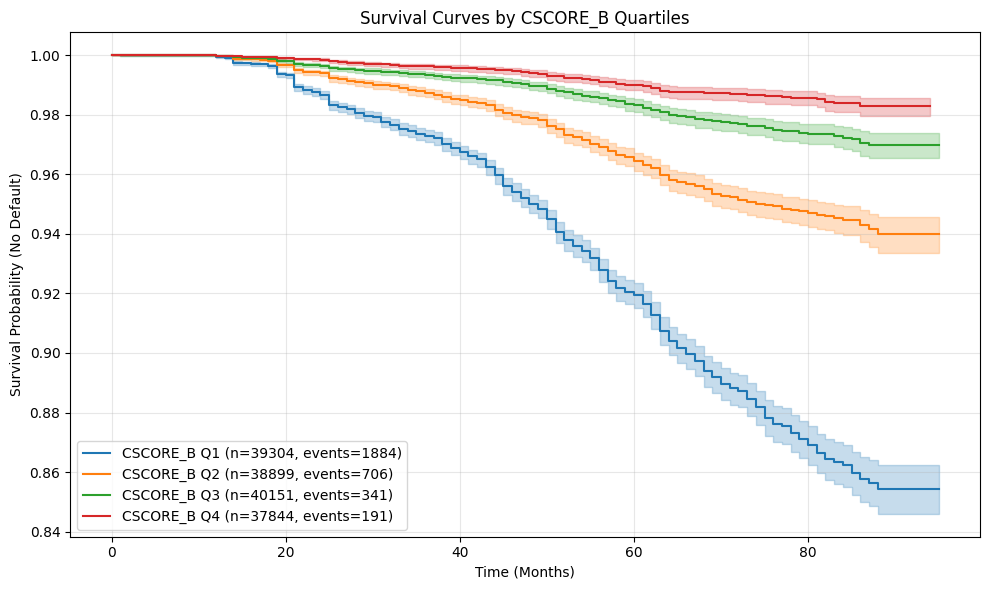

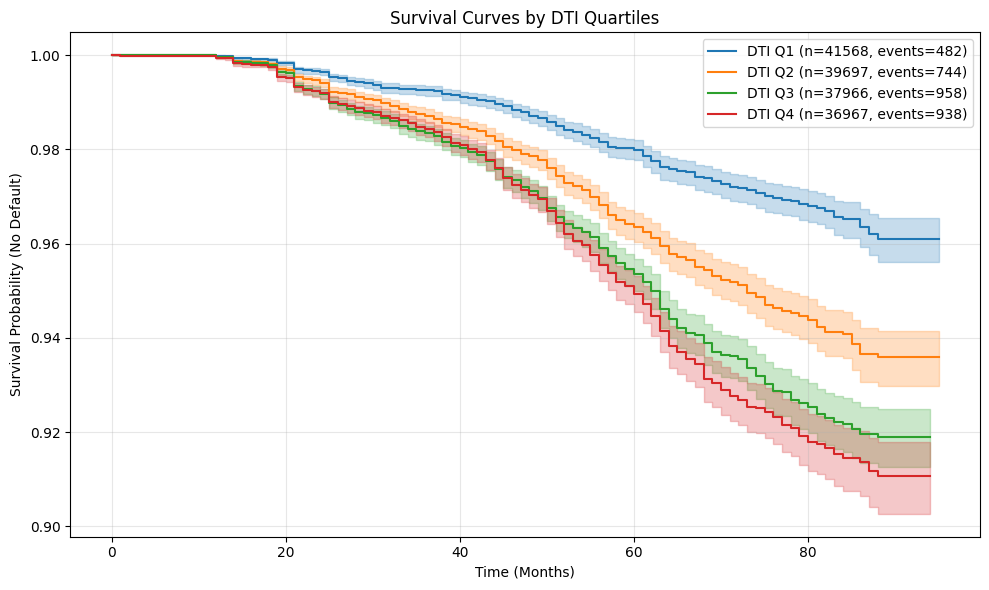

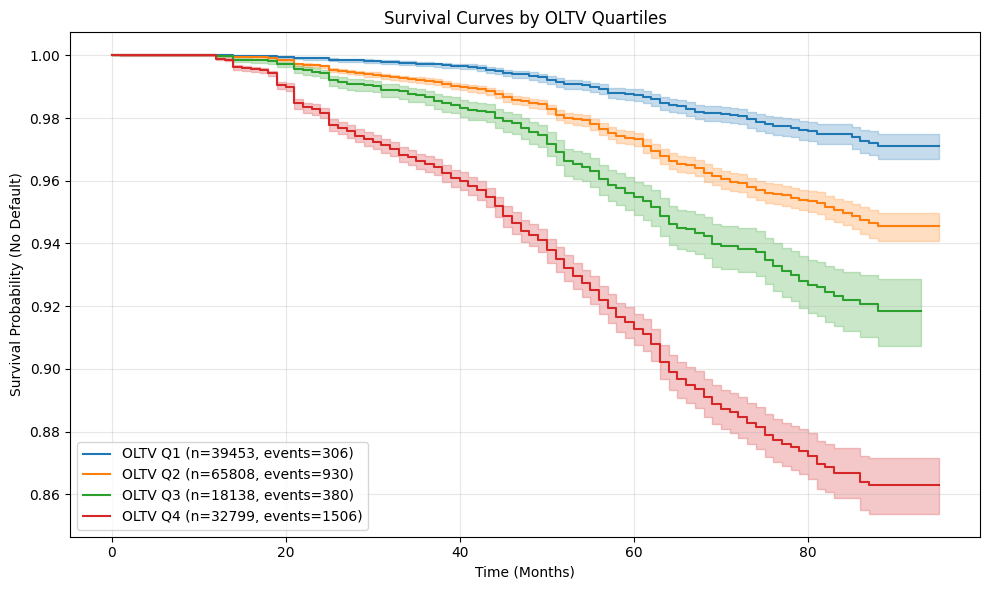

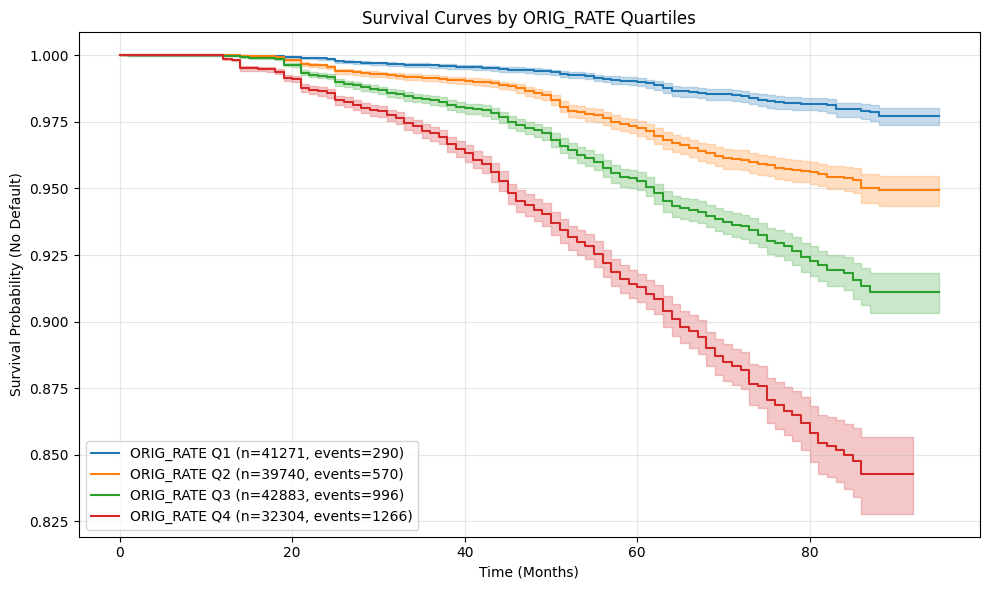

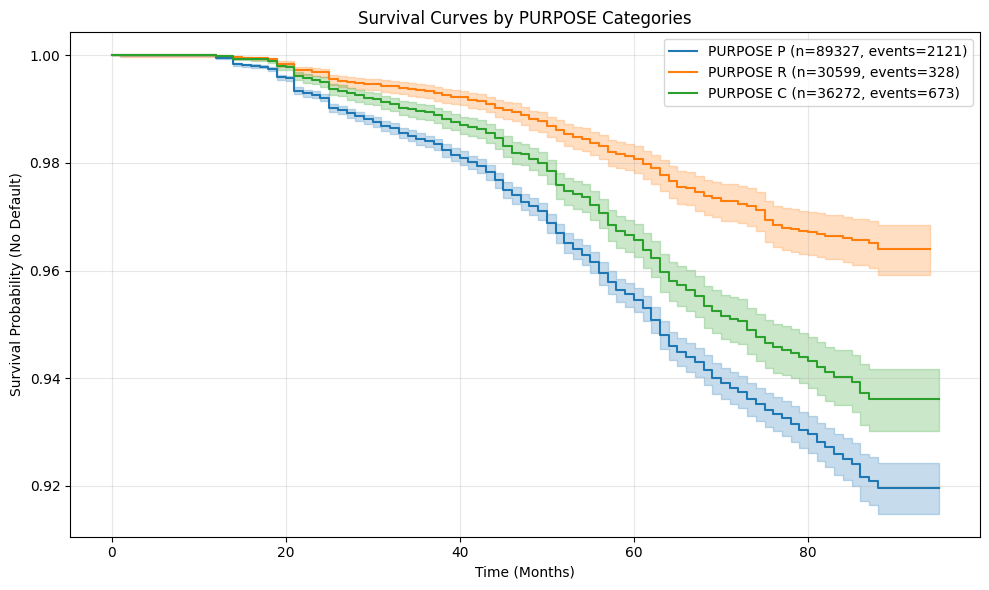


Final Results Table:
    Variable         Type   Loans  Hazard_Ratio  HR_Lower_95  HR_Upper_95  \
0   CSCORE_B   Continuous  156198         0.985        0.984        0.985   
1        DTI   Continuous  156198         1.038        1.033        1.042   
2       OLTV   Continuous  156198         1.051        1.047        1.054   
3  ORIG_RATE   Continuous  156198         3.069        2.910        3.236   
4  PURPOSE_P  Categorical  156198         1.339        1.228        1.461   
5  PURPOSE_R  Categorical  156198         0.576        0.505        0.658   

   P_value  Concordance Significant Reference_Category  
0      0.0        0.717         Yes               None  
1      0.0        0.588         Yes               None  
2      0.0        0.717         Yes               None  
3      0.0        0.716         Yes               None  
4      0.0        0.574         Yes                  P  
5      0.0        0.574         Yes                  P  


In [ ]:
import pandas as pd
import numpy as np
from lifelines import CoxPHFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

def prepare_static_analysis_data(df, loan_id_col, time_col, event_col, static_vars, orig_date_col="ORIG_DATE"):
    """
    Prepare longitudinal loan data for survival analysis using only static covariates
    """
    df = df.copy()

    # Construct observation period using exact calendar months
    df["observation_period"] = df.apply(
        lambda row: row[orig_date_col] + pd.DateOffset(months=int(row[time_col]) + 1),
        axis=1
    )

    # Sort by loan ID and time
    df_sorted = df.sort_values([loan_id_col, time_col]).copy()

    print(f"Original data: {len(df_sorted)} observations")
    print(f"Unique loans: {df_sorted[loan_id_col].nunique()}")
    print(f"Date range: {df_sorted['observation_period'].min().date()} to {df_sorted['observation_period'].max().date()}")

    # Get static variables from first observation of each loan
    static_data = df_sorted.groupby(loan_id_col)[static_vars].first().reset_index()

    # Calculate survival times and event status
    survival_info = df_sorted.groupby(loan_id_col).agg({
        time_col: ['min', 'max'],
        event_col: 'max'
    }).reset_index()

    # Flatten column names
    survival_info.columns = [loan_id_col, 'start_time', 'end_time', 'event_occurred']

    # Calculate duration (in periods)
    survival_info['duration'] = survival_info['end_time'] - survival_info['start_time']
    survival_info['duration'] = survival_info['duration'].replace(0, 1)  # avoid 0

    # Merge static vars with survival info
    analysis_df = pd.merge(static_data, survival_info, on=loan_id_col)

    print(f"Analysis data: {len(analysis_df)} loans")
    print(f"Events (defaults): {analysis_df['event_occurred'].sum()}")
    print(f"Censored loans: {len(analysis_df) - analysis_df['event_occurred'].sum()}")
    print(f"Mean duration: {analysis_df['duration'].mean():.2f} periods")

    return analysis_df

def identify_variable_types(df, variables):
    """
    Identify which variables are continuous and which are categorical
    """
    continuous_vars = []
    categorical_vars = []

    for var in variables:
        if df[var].dtype == 'object' or df[var].nunique() < 10:
            categorical_vars.append(var)
            print(f"{var}: Categorical ({df[var].nunique()} categories)")
            print(f"  Categories: {list(df[var].value_counts().index)}")
        else:
            continuous_vars.append(var)
            print(f"{var}: Continuous")

    return continuous_vars, categorical_vars

def univariate_static_cox_analysis(df, duration_col, event_col, variables):
    """
    Perform univariate Cox regression analysis for both continuous and categorical variables
    """
    results = []
    continuous_vars, categorical_vars = identify_variable_types(df, variables)

    # Handle continuous variables
    for var in continuous_vars:
        print(f"\n=== Univariate Analysis for {var} (Continuous) ===")

        # Check for missing values
        missing_pct = (df[var].isnull().sum() / len(df)) * 100
        print(f"Missing values: {missing_pct:.2f}%")

        # Basic descriptive statistics
        print(f"Mean: {df[var].mean():.3f}")
        print(f"Std: {df[var].std():.3f}")
        print(f"Min: {df[var].min():.3f}")
        print(f"Max: {df[var].max():.3f}")

        # Create temporary dataframe for this variable
        temp_df = df[[var, duration_col, event_col]].dropna()

        if len(temp_df) == 0:
            print(f"No valid observations for {var}")
            continue

        # Fit univariate Cox model
        cph = CoxPHFitter()
        cph.fit(temp_df, duration_col=duration_col, event_col=event_col)

        # Extract results
        coef = cph.summary.loc[var, 'coef']
        hr = cph.summary.loc[var, 'exp(coef)']
        p_value = cph.summary.loc[var, 'p']
        ci_lower = cph.summary.loc[var, 'exp(coef) lower 95%']
        ci_upper = cph.summary.loc[var, 'exp(coef) upper 95%']
        concordance = cph.concordance_index_

        print(f"Hazard Ratio: {hr:.3f} ({ci_lower:.3f} - {ci_upper:.3f})")
        print(f"P-value: {p_value:.6f}")
        print(f"Concordance Index: {concordance:.3f}")
        print(f"Coefficient: {coef:.3f}")

        # Interpretation
        if hr > 1:
            print(f"Interpretation: Higher {var} associated with {(hr-1)*100:.1f}% higher hazard")
        else:
            print(f"Interpretation: Higher {var} associated with {(1-hr)*100:.1f}% lower hazard")

        # Store results
        results.append({
            'Variable': var,
            'Type': 'Continuous',
            'Loans': len(temp_df),
            'Missing_Pct': missing_pct,
            'Mean': df[var].mean(),
            'Std': df[var].std(),
            'Coefficient': coef,
            'Hazard_Ratio': hr,
            'HR_Lower_95': ci_lower,
            'HR_Upper_95': ci_upper,
            'P_value': p_value,
            'Concordance': concordance,
            'Significant': 'Yes' if p_value < 0.05 else 'No',
            'Reference_Category': None
        })

    # Handle categorical variables
    for var in categorical_vars:
        print(f"\n=== Univariate Analysis for {var} (Categorical) ===")

        # Check for missing values
        missing_pct = (df[var].isnull().sum() / len(df)) * 100
        print(f"Missing values: {missing_pct:.2f}%")

        # Show category distribution
        print("Category distribution:")
        print(df[var].value_counts())

        # Create dummy variables for Cox regression
        temp_df = df[[var, duration_col, event_col]].dropna()

        if len(temp_df) == 0:
            print(f"No valid observations for {var}")
            continue

        # Create dummy variables (pandas automatically uses most frequent as reference)
        dummy_df = pd.get_dummies(temp_df[var], prefix=var, drop_first=True)

        # Combine with survival data
        cox_df = pd.concat([temp_df[[duration_col, event_col]], dummy_df], axis=1)

        # Fit univariate Cox model
        cph = CoxPHFitter()
        cph.fit(cox_df, duration_col=duration_col, event_col=event_col)

        # Get reference category (the one that was dropped)
        all_categories = sorted(temp_df[var].unique())
        reference_category = temp_df[var].value_counts().index[0]  # Most frequent category

        print(f"Reference category: {reference_category}")
        print(f"Concordance Index: {cph.concordance_index_:.3f}")

        # Extract results for each dummy variable
        for col in dummy_df.columns:
            category_name = col.replace(f"{var}_", "")

            coef = cph.summary.loc[col, 'coef']
            hr = cph.summary.loc[col, 'exp(coef)']
            p_value = cph.summary.loc[col, 'p']
            ci_lower = cph.summary.loc[col, 'exp(coef) lower 95%']
            ci_upper = cph.summary.loc[col, 'exp(coef) upper 95%']

            print(f"\n{category_name} vs {reference_category}:")
            print(f"Hazard Ratio: {hr:.3f} ({ci_lower:.3f} - {ci_upper:.3f})")
            print(f"P-value: {p_value:.6f}")
            print(f"Coefficient: {coef:.3f}")

            # Interpretation
            if hr > 1:
                print(f"Interpretation: {category_name} has {(hr-1)*100:.1f}% higher hazard vs {reference_category}")
            else:
                print(f"Interpretation: {category_name} has {(1-hr)*100:.1f}% lower hazard vs {reference_category}")

            # Store results
            results.append({
                'Variable': f"{var}_{category_name}",
                'Type': 'Categorical',
                'Loans': len(temp_df),
                'Missing_Pct': missing_pct,
                'Mean': None,
                'Std': None,
                'Coefficient': coef,
                'Hazard_Ratio': hr,
                'HR_Lower_95': ci_lower,
                'HR_Upper_95': ci_upper,
                'P_value': p_value,
                'Concordance': cph.concordance_index_,
                'Significant': 'Yes' if p_value < 0.05 else 'No',
                'Reference_Category': reference_category
            })

    return pd.DataFrame(results)

def multivariate_static_cox_analysis(df, duration_col, event_col, variables):
    """
    Perform multivariate Cox regression with both continuous and categorical variables
    """
    print("\n=== Multivariate Cox Regression Analysis ===")

    continuous_vars, categorical_vars = identify_variable_types(df, variables)

    # Start with continuous variables
    analysis_vars = continuous_vars.copy()

    # Add categorical variables as dummies
    dummy_dfs = []
    for var in categorical_vars:
        dummy_df = pd.get_dummies(df[var], prefix=var, drop_first=True)
        dummy_dfs.append(dummy_df)
        analysis_vars.extend(dummy_df.columns.tolist())

    # Create final dataframe
    base_df = df[continuous_vars + [duration_col, event_col]].copy()

    for dummy_df in dummy_dfs:
        base_df = pd.concat([base_df, dummy_df], axis=1)

    # Remove rows with missing values
    clean_df = base_df.dropna()

    print(f"Complete cases: {len(clean_df)} out of {len(df)} loans")

    # Fit multivariate Cox model
    cph = CoxPHFitter()
    cph.fit(clean_df, duration_col=duration_col, event_col=event_col)

    print(f"Concordance Index: {cph.concordance_index_:.3f}")
    print(f"Log-likelihood: {cph.log_likelihood_:.2f}")

    # Display results
    results_df = cph.summary.copy()
    results_df['HR'] = results_df['exp(coef)']
    results_df['Significant'] = results_df['p'] < 0.05

    print("\nMultivariate Results:")
    display_cols = ['coef', 'HR', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p', 'Significant']
    print(results_df[display_cols].round(4))

    return cph, results_df

def plot_survival_by_quartiles(df, duration_col, event_col, variable):
    """
    Create Kaplan-Meier survival curves by quartiles (continuous) or categories (categorical)
    """
    from lifelines import KaplanMeierFitter

    # Check if variable is categorical
    if df[variable].dtype == 'object' or df[variable].nunique() < 10:
        # For categorical variables, plot by category
        groups = df[variable].unique()
        group_col = df[variable]
        title_suffix = "Categories"
    else:
        # For continuous variables, create quartiles
        groups = pd.qcut(df[variable], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop').cat.categories
        group_col = pd.qcut(df[variable], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop')
        title_suffix = "Quartiles"

    plt.figure(figsize=(10, 6))

    kmf = KaplanMeierFitter()

    for group in groups:
        mask = group_col == group
        group_data = df.loc[mask]

        n_loans = len(group_data)
        n_events = group_data[event_col].sum()

        kmf.fit(group_data[duration_col], group_data[event_col],
                label=f'{variable} {group} (n={n_loans}, events={n_events})')
        kmf.plot_survival_function()

    plt.title(f'Survival Curves by {variable} {title_suffix}')
    plt.xlabel('Time (Months)')
    plt.ylabel('Survival Probability (No Default)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def summary_statistics_by_outcome(df, event_col, static_vars):
    """
    Compare static variables between defaulted and non-defaulted loans
    Handles both continuous and categorical variables
    """
    print("\n=== Summary Statistics by Outcome ===")

    defaulted = df[df[event_col] == 1]
    non_defaulted = df[df[event_col] == 0]

    results = []
    continuous_vars, categorical_vars = identify_variable_types(df, static_vars)

    # Handle continuous variables
    for var in continuous_vars:
        # Calculate statistics
        default_mean = defaulted[var].mean()
        non_default_mean = non_defaulted[var].mean()

        # T-test
        t_stat, p_val = stats.ttest_ind(
            defaulted[var].dropna(),
            non_defaulted[var].dropna(),
            equal_var=False
        )

        print(f"\n{var} (Continuous):")
        print(f"  Defaulted loans: {default_mean:.3f} (n={len(defaulted)})")
        print(f"  Non-defaulted:   {non_default_mean:.3f} (n={len(non_defaulted)})")
        print(f"  Difference:      {default_mean - non_default_mean:.3f}")
        print(f"  T-test p-value:  {p_val:.6f}")

        results.append({
            'Variable': var,
            'Type': 'Continuous',
            'Defaulted_Mean': default_mean,
            'Non_Defaulted_Mean': non_default_mean,
            'Difference': default_mean - non_default_mean,
            'Test_Statistic': t_stat,
            'P_value': p_val,
            'Significant': 'Yes' if p_val < 0.05 else 'No'
        })

    # Handle categorical variables
    for var in categorical_vars:
        # Chi-square test
        contingency_table = pd.crosstab(df[var], df[event_col])
        chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)

        print(f"\n{var} (Categorical):")
        print("Distribution by outcome:")

        # Calculate percentages within each outcome group
        default_dist = defaulted[var].value_counts(normalize=True) * 100
        non_default_dist = non_defaulted[var].value_counts(normalize=True) * 100

        for category in df[var].unique():
            def_pct = default_dist.get(category, 0)
            non_def_pct = non_default_dist.get(category, 0)
            print(f"  {category}: Defaulted={def_pct:.1f}%, Non-defaulted={non_def_pct:.1f}%")

        print(f"  Chi-square p-value: {p_val:.6f}")

        results.append({
            'Variable': var,
            'Type': 'Categorical',
            'Defaulted_Mean': None,
            'Non_Defaulted_Mean': None,
            'Difference': None,
            'Test_Statistic': chi2_stat,
            'P_value': p_val,
            'Significant': 'Yes' if p_val < 0.05 else 'No'
        })

    return pd.DataFrame(results)

def validate_static_assumption(df, loan_id_col, static_vars):
    """
    Check if variables are truly static within each loan
    """
    print("\n=== Validating Static Variable Assumption ===")

    for var in static_vars:
        if df[var].dtype == 'object':
            # For categorical variables, check if any loan has multiple values
            loan_categories = df.groupby(loan_id_col)[var].nunique()
            non_static_loans = (loan_categories > 1).sum()

            if non_static_loans > 0:
                print(f"WARNING: {var} varies within {non_static_loans} loans!")
            else:
                print(f"✓ {var} is static within all loans")
        else:
            # For continuous variables, calculate standard deviation within each loan
            within_loan_std = df.groupby(loan_id_col)[var].std()
            non_static_loans = (within_loan_std > 0).sum()

            if non_static_loans > 0:
                print(f"WARNING: {var} varies within {non_static_loans} loans!")
                print(f"Max within-loan std: {within_loan_std.max():.4f}")
            else:
                print(f"✓ {var} is static within all loans")


train_pd = train_data.to_pandas()
test_pd = test_data.to_pandas()
df = pd.concat([train_pd, test_pd], ignore_index=True)


# Updated main workflow
loan_id_col = 'LOAN_ID'
time_col = 'time'
event_col = 'event'
static_variables = ['CSCORE_B', 'DTI', 'OLTV', 'ORIG_RATE', 'PURPOSE']  # Added PURPOSE

# Step 1: Validate that variables are truly static
validate_static_assumption(df, loan_id_col, static_variables)

# Step 2: Prepare data (one observation per loan)
analysis_df = prepare_static_analysis_data(df, loan_id_col, time_col, event_col, static_variables)

# Step 3: Univariate analysis
univariate_results = univariate_static_cox_analysis(analysis_df, 'duration', 'event_occurred', static_variables)
print(univariate_results)

# Step 4: Multivariate analysis
multivariate_model, multivariate_results = multivariate_static_cox_analysis(
    analysis_df, 'duration', 'event_occurred', static_variables)

# Step 5: Summary statistics by outcome
outcome_summary = summary_statistics_by_outcome(analysis_df, 'event_occurred', static_variables)

# Step 6: Survival plots
for var in static_variables:
    plot_survival_by_quartiles(analysis_df, 'duration', 'event_occurred', var)

# Step 7: Create final summary table for dissertation
final_results = univariate_results[['Variable', 'Type', 'Loans', 'Hazard_Ratio', 'HR_Lower_95',
                                   'HR_Upper_95', 'P_value', 'Concordance', 'Significant', 'Reference_Category']]
print("\nFinal Results Table:")
print(final_results.round(3))

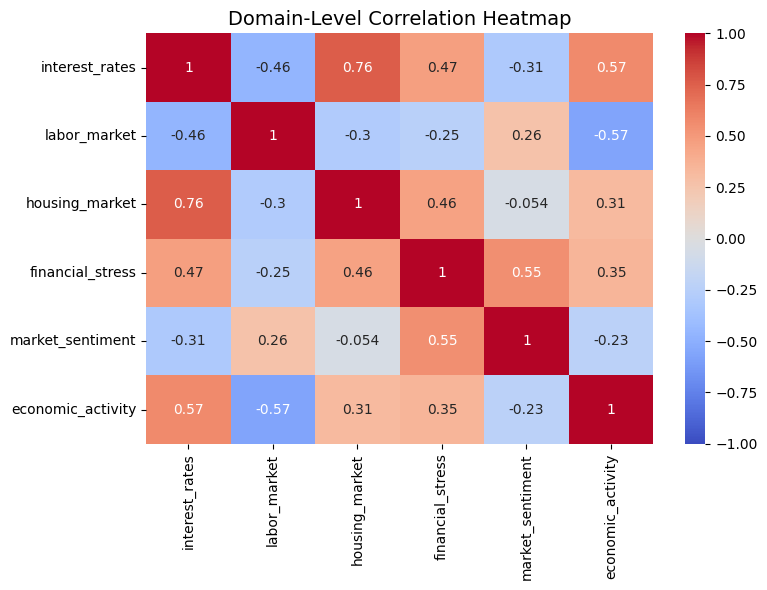

In [ ]:
import pandas as pd
import numpy as np
selected_domains = {
    'interest_rates': [
        'MORTGAGE30US_lag3','UNRATE_lag3','CSUSHPISA_lag6', 'NFCI_lag1','VIXCLS_lag1','INDPRO_lag6'
    ],
    'labor_market': [
        'UNRATE_lag3'
    ],
    'housing_market': [
        'CSUSHPISA_lag6'
    ],
    'financial_stress': [
        'NFCI_lag1'
    ],
    'market_sentiment': [
        'VIXCLS_lag1'
    ],
    'economic_activity': [
        'INDPRO_lag6'
    ]
}

# Step 1: filter macro dataset to selected variables
selected_vars = sum(selected_domains.values(), [])  # flatten list
df_macro = df[["time"] + selected_vars].drop_duplicates().dropna()

# Step 2: compute full correlation matrix
corr_matrix = df_macro[selected_vars].corr()

# Step 3: compute average correlation between domains
domain_corr = pd.DataFrame(index=selected_domains.keys(), columns=selected_domains.keys(), dtype=float)

for d1, vars1 in selected_domains.items():
    for d2, vars2 in selected_domains.items():
        sub_corr = corr_matrix.loc[vars1, vars2].values
        domain_corr.loc[d1, d2] = np.nanmean(sub_corr)

plt.figure(figsize=(8,6))
sns.heatmap(domain_corr.astype(float), annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Domain-Level Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
unique_count = df['LOAN_ID'].nunique()
print(f"Number of unique loan IDs: {unique_count}")

Number of unique loan IDs: 155470
